# 345. Does one more proteome add new local sequence? Recurring words in six QfO 2020_04 clades

## Pre-registered rule (written 2026-10-18, before any word was counted)

This cell is the first cell of notebook 345 and was committed before the pipeline counted
any word. It does not change after the run.

**Question.** We hold some proteomes from a clade. Would sequencing one more add new local
sequence, or would it mostly repeat sequence we have already seen?

**Panel.** The Quest for Orthologs (QfO) reference proteomes, release 2020_04: 78 species
from UniProt, one canonical proteome per species. One species is one independent sample.
A hidden sample is a whole proteome, so none of its sequences is seen while fitting.
Clades are NCBI taxa, fixed in `scripts/nb345_build_proteome_table.py`: Archaea (7
proteomes), Bacteria (23), Eukaryota (48), Vertebrata (13), Mammalia (8), Fungi (12). A
clade needs at least six proteomes. Viridiplantae (5) and Arthropoda (4) have too few.
The clades overlap: Mammalia sits inside Vertebrata, which sits inside Eukaryota.

**Words.** A word is a window of k residues of one protein, written in an alphabet. A
window that holds a residue other than the 20 standard amino acids is skipped. A word
*recurs* in a set of proteomes when at least two of them contain it. A word found in one
proteome only is never counted, so a one-off error or a species-private sequence does not
look like new content.

**Quantities.**

- $n$: the number of proteomes in hand; $N$: the number in the clade.
- $s$: the FracMinHash scaled value. A word is kept when its 64-bit hash is below
  $2^{64}/s$. Here $s = 1$, which keeps every word, as in every kmerseek pipeline in this repo.
- $U(n) = \frac{1}{s} \times$ (number of kept words that recur among $n$ proteomes),
  averaged over every ordering of the clade's proteomes. The average is computed exactly
  from how many proteomes hold each word, not from random orderings.
- $U_\text{null}(n)$: the same count for synthetic proteomes. Each real proteome gets one
  synthetic copy with the same protein lengths. Its residues come from a first-order Markov
  chain: each residue is drawn given only the residue before it, with the pair frequencies
  counted in that real proteome. The copy keeps the proteome's amino-acid composition and
  nothing longer than two residues.
- $U(n)/U_\text{null}(n)$: how many times more recurring words the real proteomes share
  than composition alone produces. A closed repertoire gives a flat $U(n)$ while
  $U_\text{null}(n)$ keeps growing, so the ratio falls.
- Heaps' law $U(n) = \kappa\, n^{\gamma}$. $\kappa$ (kappa) is the curve's scale, in words;
  $\gamma$ (gamma) is how fast the count grows with each added proteome. $\gamma$ near 0
  means adding proteomes adds almost nothing. Both are fitted by least squares of
  $\log U$ on $\log n$, for $n = 2, \dots, N$ ($U(1)$ is 0 by definition).

**Settings.** Two alphabets, three word budgets. Budgets are matched in bits of
information per word (`ou.bits_per_kmer`, real amino-acid frequencies):

| budget | reduced alphabet | 20-letter alphabet |
|---|---|---|
| about 21 bits | `hp_pbotc_1st_ed` k = 21 (20.9 bits) | `protein` k = 5 (20.9 bits) |
| **about 30 bits (primary)** | **`hp_pbotc_1st_ed` k = 30 (29.8 bits)** | **`protein` k = 7 (29.2 bits)** |
| about 42 bits | `hp_pbotc_1st_ed` k = 42 (41.7 bits) | `protein` k = 10 (41.8 bits) |

Only the 30-bit pair enters the verdict. The other two are reported.

**Baseline: MMseqs2 family rarefaction.** For each clade, all its proteins are clustered
with `mmseqs easy-cluster --min-seq-id 0.3 -c 0.8 --cov-mode 0` (MMseqs2 release 18,
BioContainers image pinned by digest in `nextflow-runs/proteome-novelty/main.nf`). A family
is one cluster. A family recurs when it holds proteins from at least two proteomes. $F(n)$
counts recurring families the way $U(n)$ counts recurring words. Clustering runs once per
clade on all its proteomes, hidden ones included. That can only make the MMseqs2
prediction better than it would be from the observed proteomes alone.

**Primary test: predict the next sample.**

1. In a clade of $N$ proteomes, hide the final $\lceil 0.2N \rceil$ of a random order and
   keep $n_0 = N - \lceil 0.2N \rceil$. The next sample is the first hidden proteome.
2. Draw 200 distinct (kept set, next sample) splits with a seed fixed by the clade's name,
   or take every distinct split when there are fewer than 200 (Archaea has 42, Mammalia
   56). The same splits are used for every setting and for MMseqs2.
3. Fit Heaps' law on the kept proteomes only ($n = 2, \dots, n_0$). Predicted added words
   $= \hat\kappa\,\big((n_0+1)^{\hat\gamma} - n_0^{\hat\gamma}\big)$.
4. True added words = words held by exactly one kept proteome and by the next one.
5. Relative error $= |\text{predicted} - \text{true}| / \text{true}$. A split whose true value
   is 0 is dropped and counted.
6. The statistic is the median relative error over all splits, with each clade weighted
   equally: a split weighs $1/(\text{splits in its clade})$.

**PASS** only if, at the 30-bit budget, the `hp_pbotc_1st_ed` k = 30 median is at most 0.15
**and** at most 0.75 times the MMseqs2 median (at least 25% below it). Otherwise FAIL.

**20-letter check.** If the `protein` k = 7 median is at or below the `hp_pbotc_1st_ed`
k = 30 median, the reduced alphabet adds nothing to the prediction. The application then
stands or falls on the 20-letter curve against the same two thresholds, and the case for
reduction fails.

Per-clade medians are reported and do not enter the verdict.

**Secondary test (structure).** Run only if AlphaFold models are on hand for every
proteome of the clades. This pipeline does not fetch models for the 78 proteomes, so the
secondary test is not run in notebook 345. The rule, for a later run: across clades, the
Spearman correlation of $\gamma$ (30-bit `hp_pbotc_1st_ed`) with the $\gamma$ of Foldseek
structure-cluster rarefaction passes at $\rho \ge 0.70$, and only if it beats the same
correlation for a composition baseline (the variance, across the clade's proteomes, of
their amino-acid frequencies).

**Sequencing decision, per clade.** At the 30-bit `hp_pbotc_1st_ed` setting, another
proteome is worth sequencing when the words it is predicted to add (step 3 with
$n_0 = N$) are at least 1% of $U(N)$ **and** at least twice what the synthetic proteomes
predict for their next copy. Each clade's paragraph reports $\gamma$, the predicted added
words, the null's predicted added words and $U(N)/U_\text{null}(N)$.

**Example stretch.** For the clade with the lowest $\gamma$ and the clade with the highest
$\gamma$ (30-bit `hp_pbotc_1st_ed`), name the proteome that adds the most newly recurring
words when it is added last, and print its longest stretch of such words: both sequences,
coordinates, amino-acid match line and encoded match line.

## Data

The rule above was committed as `notebooks/343_preregistration.md` (commit 9f2c402d) and
renamed when [PR 173](https://github.com/seanome/2024-kmerseek-analysis/pull/173) took
number 343 for another notebook. Its text is unchanged except for the notebook number.

- **Proteomes.** QfO reference proteomes, release 2020_04 (UniProt release 2020_04,
  12 August 2020), canonical sequences only, the copy the
  [region benchmark](https://github.com/seanome/2024-kmerseek-analysis/tree/main/nextflow-runs/qfo-pfam-region-benchmark)
  keeps on Sherlock. The pipeline's first step checks every FASTA's sequence and residue
  count against `nextflow-runs/proteome-novelty/assets/proteomes.tsv`.
- **Clades.** NCBI taxonomy dump downloaded 2026-09-13, read by
  `scripts/nb345_build_proteome_table.py`.
- **Counts.** `nextflow-runs/proteome-novelty` on this branch
  ([PR 172](https://github.com/seanome/2024-kmerseek-analysis/pull/172)). No kmerseek
  search runs: the words are counted with kmerseek's own `hp_pbotc_1st_ed` and `protein`
  letter tables, in `bin/novelty.py`, which `make test` checks against brute force.
- **MMseqs2.** Release 18 (`quay.io/biocontainers/mmseqs2:18.8cc5c--hd6d6fdc_0`),
  `easy-cluster --min-seq-id 0.3 -c 0.8 --cov-mode 0`.

**Two corrections to wording in the rule, found by the second review (the rule itself
is unchanged).** The rule says clustering MMseqs2 on hidden proteomes too "can only make
the MMseqs2 prediction better". On Archaea the review found that it helped MMseqs2 on the
median but not in every split (the review is posted on
[PR 172](https://github.com/seanome/2024-kmerseek-analysis/pull/172); its check is not
part of this notebook). And Heaps' law is fitted only on the points where $U(n) > 0$;
that matters only for synthetic proteomes at 42 bits, where few words are shared at all.

**How to read the counts.** Every count is of *recurring* words: words found in at least
two proteomes of the clade. "Real" means the QfO proteomes; "synthetic" means the
first-order Markov copies, one per real proteome, which keep amino-acid composition and
residue pairs and nothing longer. More recurring words in real than synthetic proteomes is
shared sequence that composition alone does not explain.

In [1]:
import os
import sys
from collections import Counter
from fractions import Fraction
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter, MaxNLocator, NullLocator

sys.path.insert(0, str(Path.cwd()))
import ortholog_analysis_utils as ou
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(120)
pl.Config.set_tbl_width_chars(250)
pl.Config.set_float_precision(3)

REPO = Path.cwd().parent
DATA = Path(os.environ.get("NB345_DIR", REPO / "tables" / "345"))
FIG = Path(os.environ.get("NB345_FIG", REPO / "figures" / "345"))
TABLE = REPO / "nextflow-runs" / "proteome-novelty" / "assets" / "proteomes.tsv"

# From the pre-registered rule (first cell).
CLADES = ["Archaea", "Bacteria", "Eukaryota", "Fungi", "Vertebrata", "Mammalia"]
HP, AA, FAMILY = "hp_pbotc_1st_ed", "protein", "mmseqs.family"
BUDGETS = {
    21: (f"{HP}.21", f"{AA}.5"),
    30: (f"{HP}.30", f"{AA}.7"),
    42: (f"{HP}.42", f"{AA}.10"),
}
PRIMARY_HP, PRIMARY_AA = BUDGETS[30]
PASS_MAX_ERROR = 0.15  # median relative error at most this
MUST_BEAT_MMSEQS = 0.75  # and at most this times the MMseqs2 median
DECIDE_MIN_SHARE = 0.01  # sequence another if it adds at least 1% of U(N) ...
DECIDE_NULL_FOLD = 2.0  # ... and at least twice what the synthetic proteomes add

# One colour per alphabet, kept in every figure. Real proteomes: full colour; synthetic: a
# light tint of the same hue. MMseqs2 families: black.
COLOUR = {
    HP: pf.OKABE_ITO["blue"],
    AA: pf.OKABE_ITO["vermillion"],
    FAMILY: pf.OKABE_ITO["black"],
}
TINT = {HP: "#8fbfe0", AA: "#f0b48a"}
LABEL = {
    PRIMARY_HP: f"{HP} k30 (2 letters, 29.8 bits)",
    PRIMARY_AA: f"{AA} k7 (20 letters, 29.2 bits)",
    FAMILY: "MMseqs2 families (30% identity, 80% coverage)",
}
for budget, (h, a) in BUDGETS.items():
    print(
        f"{budget}-bit budget: {h} = {ou.bits_per_kmer(HP, int(h.split('.')[1])):.2f} bits, "
        f"{a} = {ou.bits_per_kmer('protein', int(a.split('.')[1])):.2f} bits"
    )

proteomes = pl.read_csv(TABLE, separator="\t")
curve = pl.read_parquet(DATA / "345_curve.parquet")
fit = pl.read_parquet(DATA / "345_fit.parquet")
splits = pl.read_parquet(DATA / "345_splits.parquet")
last = pl.read_parquet(DATA / "345_last.parquet")
examples = pl.read_parquet(DATA / "345_examples.parquet")
words = pl.read_parquet(DATA / "345_word_summary.parquet")

expected = [
    f"{kind}.{s}"
    for s in sum(map(list, BUDGETS.values()), [])
    for kind in ("real", "null")
]
expected += [f"real.{FAMILY}"]
found = set(zip(fit["clade"], fit["setting"]))
missing = [(c, s) for c in CLADES for s in expected if (c, s) not in found]
print(f"\nData: {DATA}")
print(f"{len(found)} of {len(CLADES) * len(expected)} clade x setting results present.")
print("Missing:", missing if missing else "none")
print("Example stretches for:", sorted(examples["clade"].unique()))

21-bit budget: hp_pbotc_1st_ed.21 = 20.87 bits, protein.5 = 20.88 bits
30-bit budget: hp_pbotc_1st_ed.30 = 29.81 bits, protein.7 = 29.23 bits
42-bit budget: hp_pbotc_1st_ed.42 = 41.74 bits, protein.10 = 41.76 bits

Data: /Users/olga/code/2024-kmerseek-analysis/.claude/worktrees/nb343-proteome-novelty/tables/345
78 of 78 clade x setting results present.
Missing: none
Example stretches for: ['Archaea', 'Bacteria', 'Eukaryota', 'Fungi', 'Mammalia', 'Vertebrata']


## 1. The panel

Each clade's proteomes and their sizes. Bigger proteomes have more windows, so more words
can recur by chance; the synthetic copies have the same sizes, which is what makes them a
fair chance level.

shape: (6, 6)
┌────────────┬───────────┬──────────┬───────────┬──────────┬─────────┐
│ clade      ┆ proteomes ┆ proteins ┆ residues  ┆ smallest ┆ largest │
│ ---        ┆ ---       ┆ ---      ┆ ---       ┆ ---      ┆ ---     │
│ str        ┆ i64       ┆ i64      ┆ i64       ┆ str      ┆ str     │
╞════════════╪═══════════╪══════════╪═══════════╪══════════╪═════════╡
│ Archaea    ┆ 7         ┆ 17314    ┆ 5011522   ┆ KORCO    ┆ METAC   │
│ Bacteria   ┆ 23        ┆ 82585    ┆ 26795071  ┆ MYCGE    ┆ STRCO   │
│ Eukaryota  ┆ 48        ┆ 884238   ┆ 408440341 ┆ SCHPO    ┆ PARTE   │
│ Fungi      ┆ 12        ┆ 111213   ┆ 50083832  ┆ SCHPO    ┆ PUCGT   │
│ Vertebrata ┆ 13        ┆ 277761   ┆ 149302905 ┆ XENTR    ┆ DANRE   │
│ Mammalia   ┆ 8         ┆ 174740   ┆ 92494528  ┆ RAT      ┆ BOVIN   │
└────────────┴───────────┴──────────┴───────────┴──────────┴─────────┘


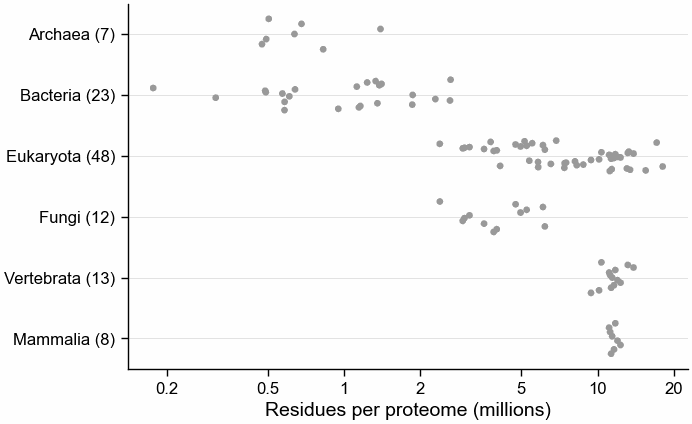

In [2]:
def clade_members(clade):
    return proteomes.filter(pl.col("clades").str.split(",").list.contains(clade))


panel = pl.DataFrame(
    [
        {
            "clade": c,
            "proteomes": clade_members(c).height,
            "proteins": int(clade_members(c)["n_sequences"].sum()),
            "residues": int(clade_members(c)["n_residues"].sum()),
            "smallest": clade_members(c).sort("n_residues")["oscode"][0],
            "largest": clade_members(c).sort("n_residues")["oscode"][-1],
        }
        for c in CLADES
    ]
)
print(panel)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
for i, c in enumerate(CLADES):
    m = clade_members(c)
    y = np.full(m.height, i) + np.linspace(-0.25, 0.25, m.height)
    ax.scatter(m["n_residues"] / 1e6, y, s=6, color=pf.GREY, edgecolor="none")
ax.set_yticks(range(len(CLADES)), [f"{c} ({clade_members(c).height})" for c in CLADES])
ax.set_ylim(len(CLADES) - 0.5, -0.5)
ax.set_xscale("log")
ax.xaxis.set_major_locator(FixedLocator([0.2, 0.5, 1, 2, 5, 10, 20]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xlabel("Residues per proteome (millions)")
ax.grid(axis="y", color="#dddddd", lw=0.3)
pf.save(fig, FIG / "345_SF1_proteome_sizes_by_clade_qfo2020_04")

**Supplementary Figure 1 (SF1). Proteome sizes in each clade.** One grey dot per QfO
2020_04 proteome; the number of proteomes is beside each clade name. The x axis spaces
values by ratio: the step from 1 to 2 million takes as much room as the step from 10 to 20
million. The clades overlap: every Mammalia proteome is also in Vertebrata and Eukaryota.

## 2. Discovery curves

$U(n)$, the number of words found in at least two of $n$ proteomes, averaged over every
order in which the clade's proteomes could be added. Real proteomes against their
synthetic copies, and the two-letter alphabet against the 20 amino acids, at the 30-bit
budget.

How to read it: where the real curve runs far above its synthetic curve, proteomes share
sequence beyond composition. A real curve that flattens while the synthetic one keeps
rising is a clade whose shared repertoire is closing.

shape: (24, 4)
┌────────────┬─────────────────────────┬─────┬──────────────┐
│ clade      ┆ setting                 ┆ N   ┆ U(N)         │
│ ---        ┆ ---                     ┆ --- ┆ ---          │
│ str        ┆ str                     ┆ i64 ┆ f64          │
╞════════════╪═════════════════════════╪═════╪══════════════╡
│ Archaea    ┆ real.hp_pbotc_1st_ed.30 ┆ 7   ┆ 31162.000    │
│ Archaea    ┆ null.hp_pbotc_1st_ed.30 ┆ 7   ┆ 8182.000     │
│ Archaea    ┆ real.protein.7          ┆ 7   ┆ 86872.000    │
│ Archaea    ┆ null.protein.7          ┆ 7   ┆ 36255.000    │
│ Bacteria   ┆ real.hp_pbotc_1st_ed.30 ┆ 23  ┆ 548470.000   │
│ Bacteria   ┆ null.hp_pbotc_1st_ed.30 ┆ 23  ┆ 258284.000   │
│ Bacteria   ┆ real.protein.7          ┆ 23  ┆ 1589383.000  │
│ Bacteria   ┆ null.protein.7          ┆ 23  ┆ 1138016.000  │
│ Eukaryota  ┆ real.hp_pbotc_1st_ed.30 ┆ 48  ┆ 51192968.000 │
│ Eukaryota  ┆ null.hp_pbotc_1st_ed.30 ┆ 48  ┆ 60069696.000 │
│ Eukaryota  ┆ real.protein.7          ┆ 48  ┆ 58500329

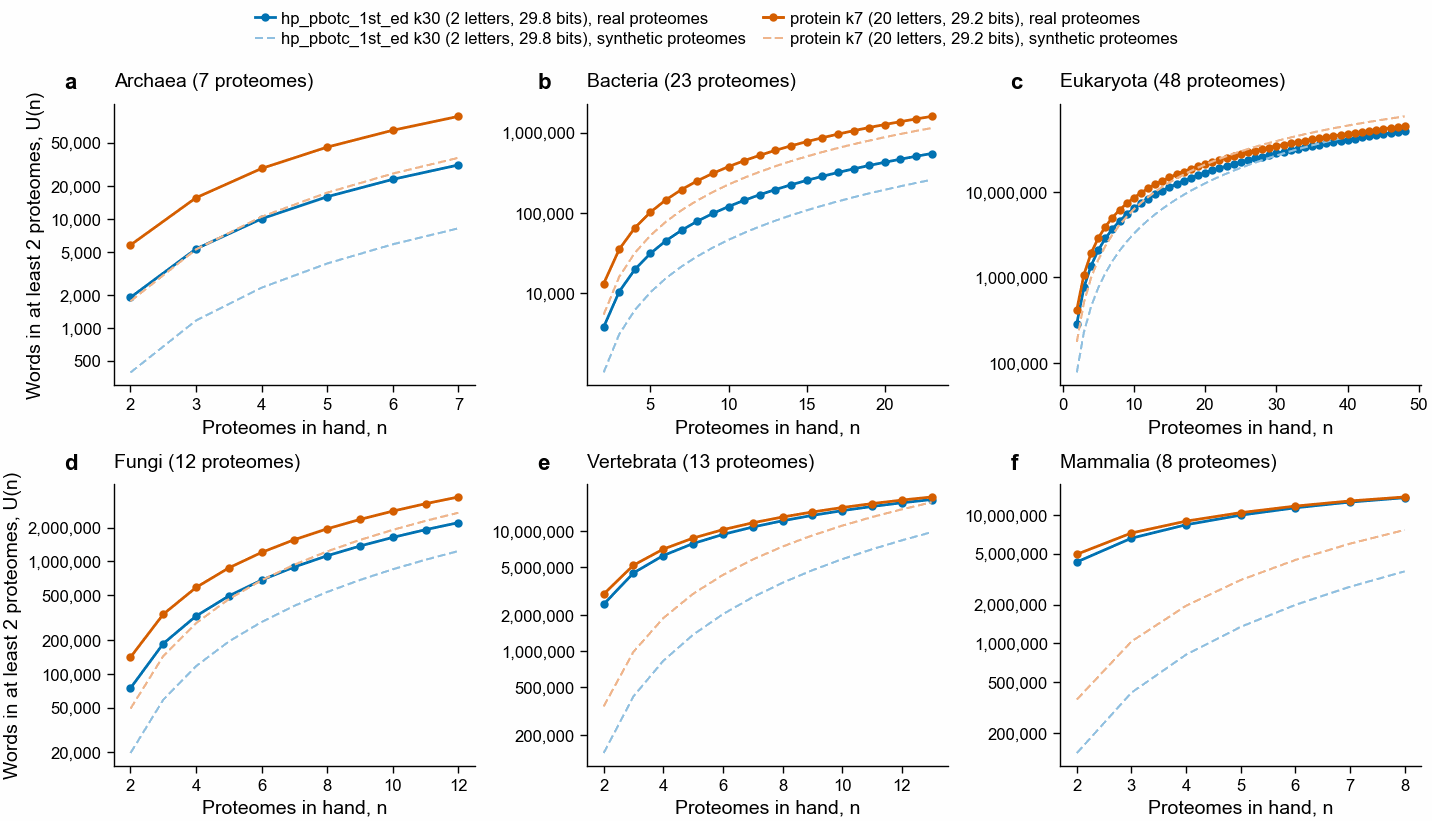

In [3]:
def curve_of(clade, setting):
    return curve.filter(
        (pl.col("clade") == clade) & (pl.col("setting") == setting)
    ).sort("n")


def plain_log_axis(axis, lo, hi):
    ticks = [
        m * 10**e for e in range(0, 10) for m in (1, 2, 5) if lo <= m * 10**e <= hi
    ]
    if len(ticks) > 7:  # keep powers of ten only when the range is wide
        ticks = [t for t in ticks if str(int(t)).startswith("1")]
    axis.set_major_locator(FixedLocator(ticks))
    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    axis.set_minor_locator(NullLocator())


fig, axs = pf.figure(pf.TWO_COLUMN_MM, 105, nrows=2, ncols=3)
rows = []
for ax, c in zip(axs.flat, CLADES):
    ymin, ymax = np.inf, 0
    for alph, s in ((HP, PRIMARY_HP), (AA, PRIMARY_AA)):
        for kind in ("real", "null"):
            d = curve_of(c, f"{kind}.{s}").filter(pl.col("U") > 0)
            if d.height == 0:
                continue
            real = kind == "real"
            ax.plot(
                d["n"],
                d["U"],
                color=COLOUR[alph] if real else TINT[alph],
                lw=1 if real else 0.8,
                ls="-" if real else "--",
                marker="o" if real else None,
                ms=2,
                label=f"{LABEL[s]}, {'real' if real else 'synthetic'} proteomes",
            )
            ymin, ymax = min(ymin, d["U"].min()), max(ymax, d["U"].max())
            rows.append(
                {
                    "clade": c,
                    "setting": f"{kind}.{s}",
                    "N": int(d["n"].max()),
                    "U(N)": float(d["U"][-1]),
                }
            )
    ax.set_yscale("log")
    plain_log_axis(ax.yaxis, ymin, ymax)
    ax.set_title(f"{c} ({clade_members(c).height} proteomes)", loc="left")
    ax.set_xlabel("Proteomes in hand, n")
    ax.set_ylabel("Words in at least 2 proteomes, U(n)" if ax in axs[:, 0] else "")
pf.shared_legend(fig, ncol=2)
for ax, letter in zip(axs.flat, "abcdef"):
    pf.panel_label(ax, letter)
pf.save(
    fig, FIG / "345_SF2_discovery_curves_real_vs_synthetic_hp30_protein7_qfo2020_04"
)
print(pl.DataFrame(rows))

**Supplementary Figure 2 (SF2). Words shared by at least two proteomes, as proteomes are
added, in six QfO 2020_04 clades.** Blue: the two-letter hydrophobic/polar alphabet
`hp_pbotc_1st_ed` (hydrophobic `ACFILMPVWY`, polar `DEGHKNQRST`) at k = 30. Orange: the 20
amino acids at k = 7. Both carry about 30 bits per word. Solid lines with dots: the real
proteomes. Light dashed lines: one synthetic copy per proteome, same protein lengths, each
residue drawn given only the one before it. Each curve is the exact average over every
order of adding the proteomes. The y axis spaces values by ratio. No kmerseek search;
word counts from `bin/novelty.py`. A curve that runs above its dashed copy means shared
sequence beyond composition; higher above it is more shared sequence.

### 2b. Real against synthetic, as a ratio

$U(n)/U_\text{null}(n)$ for each clade. A ratio of 1 means the real proteomes share no
more words than composition gives. A falling ratio means the synthetic count is catching
up: each new real proteome adds fewer shared words than chance would.

shape: (12, 5)
┌────────────┬────────────────────┬────────────┬────────────┬─────────────────────┐
│ clade      ┆ setting            ┆ ratio_at_2 ┆ ratio_at_N ┆ n_with_null_above_0 │
│ ---        ┆ ---                ┆ ---        ┆ ---        ┆ ---                 │
│ str        ┆ str                ┆ f64        ┆ f64        ┆ i64                 │
╞════════════╪════════════════════╪════════════╪════════════╪═════════════════════╡
│ Archaea    ┆ hp_pbotc_1st_ed.30 ┆ 4.876      ┆ 3.809      ┆ 6                   │
│ Archaea    ┆ protein.7          ┆ 3.273      ┆ 2.396      ┆ 6                   │
│ Bacteria   ┆ hp_pbotc_1st_ed.30 ┆ 3.672      ┆ 2.124      ┆ 22                  │
│ Bacteria   ┆ protein.7          ┆ 2.426      ┆ 1.397      ┆ 22                  │
│ Eukaryota  ┆ hp_pbotc_1st_ed.30 ┆ 3.734      ┆ 0.852      ┆ 47                  │
│ Eukaryota  ┆ protein.7          ┆ 2.363      ┆ 0.768      ┆ 47                  │
│ Fungi      ┆ hp_pbotc_1st_ed.30 ┆ 3.786      ┆ 1.790      ┆

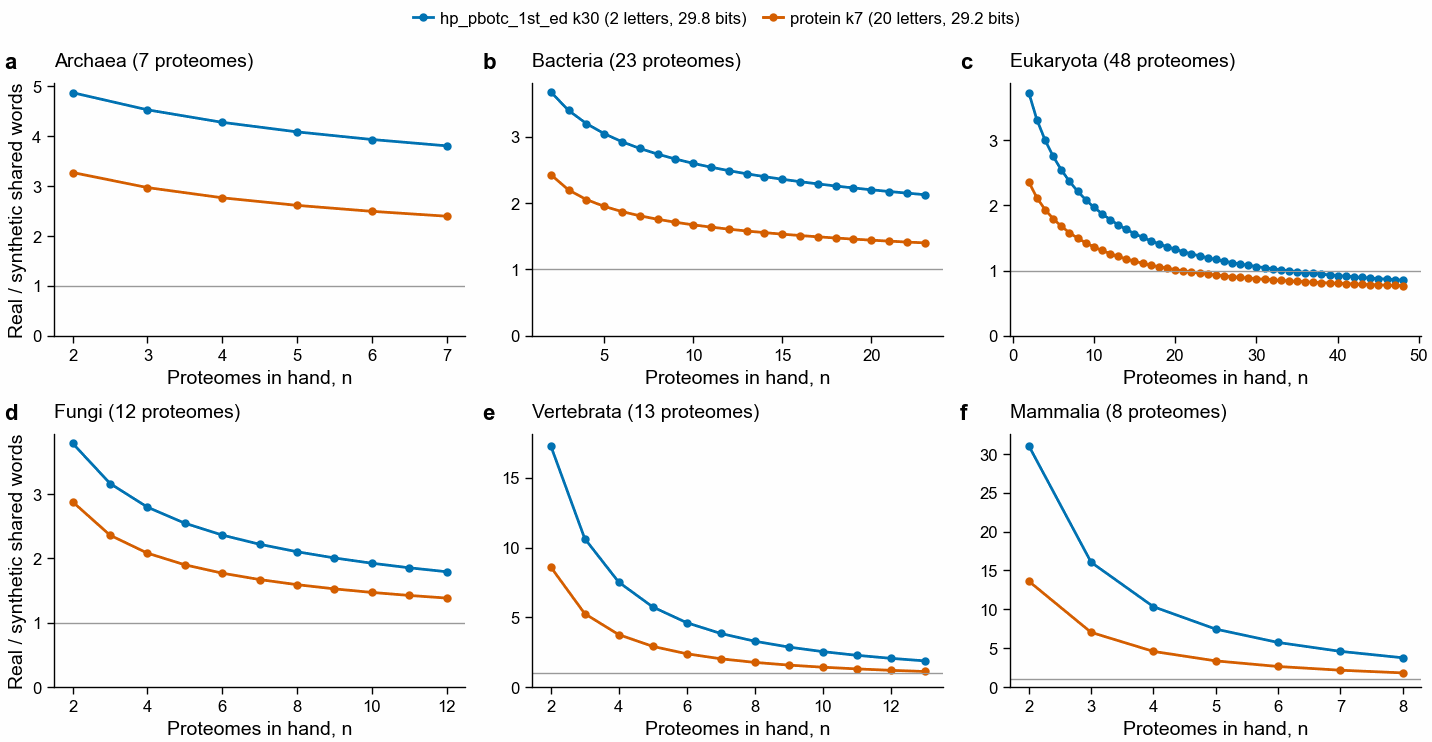

In [4]:
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, nrows=2, ncols=3)
rows = []
for ax, c in zip(axs.flat, CLADES):
    for alph, s in ((HP, PRIMARY_HP), (AA, PRIMARY_AA)):
        r, nl = curve_of(c, f"real.{s}"), curve_of(c, f"null.{s}")
        if r.height == 0 or nl.height == 0:
            continue
        d = r.join(nl, on="n", suffix="_null").filter(pl.col("U_null") > 0)
        ratio = d["U"] / d["U_null"]
        ax.plot(d["n"], ratio, color=COLOUR[alph], marker="o", ms=2, label=LABEL[s])
        rows.append(
            {
                "clade": c,
                "setting": s,
                "ratio_at_2": float(ratio[0]) if d.height else None,
                "ratio_at_N": float(ratio[-1]) if d.height else None,
                "n_with_null_above_0": d.height,
            }
        )
    ax.axhline(1, color=pf.GREY, lw=0.5)
    ax.set_title(f"{c} ({clade_members(c).height} proteomes)", loc="left")
    ax.set_xlabel("Proteomes in hand, n")
    ax.set_ylabel("Real / synthetic shared words" if ax in axs[:, 0] else "")
    ax.set_ylim(bottom=0)
pf.shared_legend(fig, ncol=2)
for ax, letter in zip(axs.flat, "abcdef"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG / "345_SF3_real_over_synthetic_shared_words_hp30_protein7_qfo2020_04")
ratio_table = pl.DataFrame(rows)
print(ratio_table)

budget_rows = []
for c in CLADES:
    for budget, pair in BUDGETS.items():
        for s in pair:
            r, nl = curve_of(c, f"real.{s}"), curve_of(c, f"null.{s}")
            if r.height and nl.height:
                budget_rows.append(
                    {
                        "clade": c,
                        "budget_bits": budget,
                        "setting": s,
                        "U(N)": float(r["U"][-1]),
                        "U_null(N)": float(nl["U"][-1]),
                        "ratio_at_N": (
                            float(r["U"][-1] / nl["U"][-1]) if nl["U"][-1] > 0 else None
                        ),
                    }
                )
print("\nAll three budgets, full clade (not part of the verdict):")
print(pl.DataFrame(budget_rows))

**Supplementary Figure 3 (SF3). How many times more words real proteomes share than their
synthetic copies.** Same data as SF2, same colours. The grey line at 1 is no excess over
composition. Points where the synthetic proteomes share no word at all are left out (the
ratio has no value there); the table under the figure says how many points each line
has. The second table gives the 21- and 42-bit budgets, which are reported and do not
enter the verdict.

### 2c. Why synthetic Eukaryota proteomes share more words than real ones

Found by the adversarial check on PR 172. There are $2^{30}$ = 1,073,741,824 possible
`hp_pbotc_1st_ed` words of 30 letters. The 48 Eukaryota proteomes hold 382,612,416 windows
of 30 residues, about a third of that number, so two random proteomes already share many
words by chance. `scripts/nb345_chance_collisions.py` computes how many words would be
shared by at least two proteomes if each proteome's words came from a two-letter Markov
chain with that proteome's own h/p pair frequencies. It does not use `bin/novelty.py`.
If this chance count matches the synthetic count, the synthetic proteomes are what they
should be and the ratio below 1 is not a bug.

shape: (6, 12)
┌────────────┬─────────────┬───────────┬───────────────────────────┬───────────────────┬────────────────────┬───────────────────────┬───────────────┬─────────────────────┬───────────────────┬────────────────────┬───────────────┐
│ clade      ┆ n_proteomes ┆ windows   ┆ windows_per_possible_word ┆ expected_shared_N ┆ synthetic_shared_N ┆ synthetic_over_chance ┆ real_shared_N ┆ real_over_synthetic ┆ expected_distinct ┆ synthetic_distinct ┆ real_distinct │
│ ---        ┆ ---         ┆ ---       ┆ ---                       ┆ ---               ┆ ---                ┆ ---                   ┆ ---           ┆ ---                 ┆ ---               ┆ ---                ┆ ---           │
│ str        ┆ i64         ┆ i64       ┆ f64                       ┆ f64               ┆ f64                ┆ f64                   ┆ f64           ┆ f64                 ┆ f64               ┆ i64                ┆ i64           │
╞════════════╪═════════════╪═══════════╪═══════════════════════════╪═

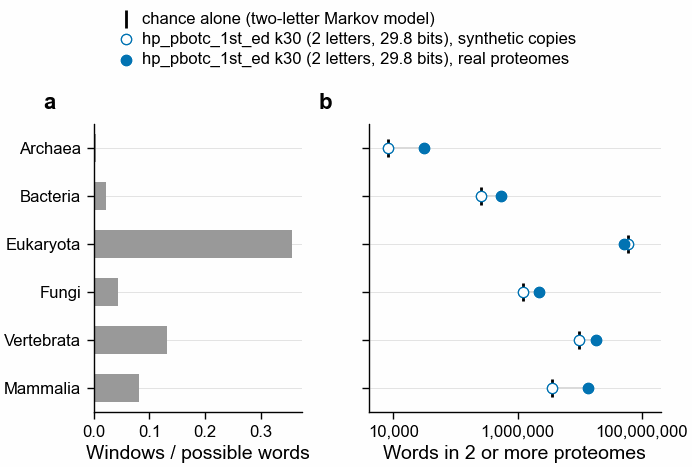

In [5]:
chance = pl.read_parquet(DATA / "345_chance_collisions.parquet")
comp = pl.read_parquet(DATA / "345_chance_hp_composition.parquet")
u_full = (
    fit.filter(pl.col("setting").is_in([f"real.{PRIMARY_HP}", f"null.{PRIMARY_HP}"]))
    .select(
        "clade", pl.col("setting").str.split(".").list.first().alias("kind"), "U_full"
    )
    .pivot(on="kind", index="clade", values="U_full")
)
distinct = words.filter((pl.col("alphabet") == HP) & (pl.col("ksize") == 30)).pivot(
    on="kind", index="clade", values="n_distinct_words"
)
chance_table = (
    chance.join(
        u_full.rename({"real": "real_shared_N", "null": "synthetic_shared_N"}),
        on="clade",
    )
    .join(
        distinct.rename({"real": "real_distinct", "null": "synthetic_distinct"}),
        on="clade",
    )
    .with_columns(
        (pl.col("windows") / pl.col("possible_words")).alias(
            "windows_per_possible_word"
        ),
        (pl.col("synthetic_shared_N") / pl.col("expected_shared_N")).alias(
            "synthetic_over_chance"
        ),
        (pl.col("real_shared_N") / pl.col("synthetic_shared_N")).alias(
            "real_over_synthetic"
        ),
    )
    .select(
        "clade",
        "n_proteomes",
        "windows",
        "windows_per_possible_word",
        "expected_shared_N",
        "synthetic_shared_N",
        "synthetic_over_chance",
        "real_shared_N",
        "real_over_synthetic",
        "expected_distinct",
        "synthetic_distinct",
        "real_distinct",
    )
)
print(chance_table)
euk = comp.filter(pl.col("clades").str.split(",").list.contains("Eukaryota"))
print(
    f"\nEukaryota h fraction per proteome: {euk['h_fraction'].min():.3f} "
    f"({euk.sort('h_fraction')['oscode'][0]}) to {euk['h_fraction'].max():.3f} "
    f"({euk.sort('h_fraction')['oscode'][-1]})"
)

fig, axs = pf.figure(pf.ONE_COLUMN_MM, 60, ncols=2, sharey=True, width_ratios=[1, 1.4])
y = {c: i for i, c in enumerate(CLADES)}
for r in chance_table.iter_rows(named=True):
    axs[0].barh(
        y[r["clade"]], r["windows_per_possible_word"], color=pf.GREY, height=0.6
    )
    axs[1].plot(
        [r["expected_shared_N"], r["real_shared_N"]],
        [y[r["clade"]]] * 2,
        color="#dddddd",
        lw=0.8,
        zorder=0,
    )
axs[0].set_xlabel("Windows / possible words")
axs[0].set_yticks(range(len(CLADES)), CLADES)
axs[0].set_ylim(len(CLADES) - 0.5, -0.5)
ys = [y[c] for c in chance_table["clade"]]
axs[1].scatter(
    chance_table["expected_shared_N"],
    ys,
    marker="|",
    s=40,
    color="black",
    label="chance alone (two-letter Markov model)",
)
axs[1].scatter(
    chance_table["synthetic_shared_N"],
    ys,
    marker="o",
    s=14,
    facecolor="white",
    edgecolor=COLOUR[HP],
    label=f"{LABEL[PRIMARY_HP]}, synthetic copies",
)
axs[1].scatter(
    chance_table["real_shared_N"],
    ys,
    marker="o",
    s=14,
    color=COLOUR[HP],
    label=f"{LABEL[PRIMARY_HP]}, real proteomes",
)
axs[1].set_xscale("log")
axs[1].set_xlim(4_000, 2e8)
axs[1].xaxis.set_major_locator(FixedLocator([1e4, 1e6, 1e8]))
axs[1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
axs[1].xaxis.set_minor_locator(NullLocator())
axs[1].set_xlabel("Words in 2 or more proteomes")
for ax in axs:
    ax.grid(axis="y", color="#dddddd", lw=0.3)
pf.shared_legend(fig, ncol=1)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG / "345_SF3b_chance_shared_words_vs_synthetic_real_hp30_qfo2020_04")

**Supplementary Figure 3b (SF3b). The synthetic proteomes share exactly as many words as
chance predicts; in Eukaryota, chance alone outnumbers the real shared words.** a, the
clade's windows of 30 residues divided by the $2^{30}$ possible `hp_pbotc_1st_ed` words.
b, words held by at least two of the clade's N proteomes (all of them, not a subset). Black tick: the number expected
by chance, from a two-letter Markov model of each proteome (`scripts/nb345_chance_collisions.py`);
open blue circle: the synthetic copies; filled blue circle: the real proteomes. The x axis
spaces values by ratio. The open circle sits on the tick in every clade, so the synthetic
proteomes have no bug. The real proteomes hold fewer distinct words than their copies
(the table's last two columns), because proteins repeat words within a proteome, so fewer
of their words are left to match another proteome by chance. When the windows fill a third
of all possible words, as in Eukaryota, that loss outweighs the shared sequence. At this
budget, a ratio of real to synthetic below 1 does not mean the real proteomes share less
sequence; at 42 bits, where chance matches are rare, the Eukaryota ratio is 781 (section 2b table).

## 3. Heaps' law

$U(n) = \kappa\, n^{\gamma}$ fitted to each full-clade curve, $n = 2, \dots, N$. With this
count, a word needs two proteomes to be counted, so if every pair of proteomes shared the
same number of words, $U(n)$ would grow with the number of pairs, $n(n-1)/2$, and $\gamma$
would be near 2. The synthetic proteomes show that chance level. A real $\gamma$ well
below its synthetic $\gamma$ means each new proteome mostly finds words that are already
shared.

shape: (78, 7)
┌────────────┬───────────┬────────────────────┬──────┬─────────────┬───────┬──────────────┐
│ clade      ┆ proteomes ┆ words              ┆ size ┆ kappa       ┆ gamma ┆ U_full       │
│ ---        ┆ ---       ┆ ---                ┆ ---  ┆ ---         ┆ ---   ┆ ---          │
│ str        ┆ str       ┆ str                ┆ i64  ┆ f64         ┆ f64   ┆ f64          │
╞════════════╪═══════════╪════════════════════╪══════╪═════════════╪═══════╪══════════════╡
│ Archaea    ┆ null      ┆ hp_pbotc_1st_ed.21 ┆ 7    ┆ 51002.521   ┆ 1.699 ┆ 1239114.000  │
│ Archaea    ┆ real      ┆ hp_pbotc_1st_ed.21 ┆ 7    ┆ 53009.547   ┆ 1.620 ┆ 1113364.000  │
│ Archaea    ┆ null      ┆ hp_pbotc_1st_ed.30 ┆ 7    ┆ 77.865      ┆ 2.418 ┆ 8182.000     │
│ Archaea    ┆ real      ┆ hp_pbotc_1st_ed.30 ┆ 7    ┆ 437.084     ┆ 2.220 ┆ 31162.000    │
│ Archaea    ┆ null      ┆ hp_pbotc_1st_ed.42 ┆ 7    ┆ 0.047       ┆ 2.419 ┆ 5.000        │
│ Archaea    ┆ real      ┆ hp_pbotc_1st_ed.42 ┆ 7    ┆ 73.888    

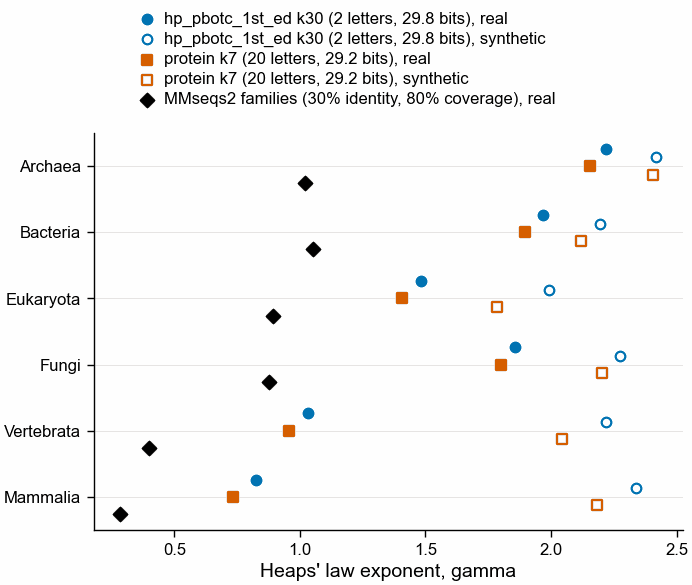

In [6]:
def gamma_of(clade, setting):
    d = fit.filter((pl.col("clade") == clade) & (pl.col("setting") == setting))
    return float(d["gamma"][0]) if d.height else np.nan


gamma_table = (
    fit.with_columns(
        pl.col("setting").str.split(".").list.first().alias("proteomes"),
        pl.col("setting").str.split(".").list.slice(1).list.join(".").alias("words"),
    )
    .select("clade", "proteomes", "words", "size", "kappa", "gamma", "U_full")
    .sort("clade", "words", "proteomes")
)
print(gamma_table)

marks = [  # (setting, colour, marker, filled, label)
    (f"real.{PRIMARY_HP}", COLOUR[HP], "o", True, f"{LABEL[PRIMARY_HP]}, real"),
    (f"null.{PRIMARY_HP}", COLOUR[HP], "o", False, f"{LABEL[PRIMARY_HP]}, synthetic"),
    (f"real.{PRIMARY_AA}", COLOUR[AA], "s", True, f"{LABEL[PRIMARY_AA]}, real"),
    (f"null.{PRIMARY_AA}", COLOUR[AA], "s", False, f"{LABEL[PRIMARY_AA]}, synthetic"),
    (f"real.{FAMILY}", COLOUR[FAMILY], "D", True, f"{LABEL[FAMILY]}, real"),
]
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 75)
for j, (s, col, mk, filled, lab) in enumerate(marks):
    y = np.arange(len(CLADES)) + (j - 2) * 0.13
    g = [gamma_of(c, s) for c in CLADES]
    ax.scatter(
        g,
        y,
        marker=mk,
        s=12,
        facecolor=col if filled else "white",
        edgecolor=col,
        lw=0.8,
        label=lab,
    )
ax.set_yticks(range(len(CLADES)), CLADES)
ax.set_ylim(len(CLADES) - 0.5, -0.5)
ax.grid(axis="y", color="#dddddd", lw=0.3)
ax.set_xlabel("Heaps' law exponent, gamma")
pf.shared_legend(fig, ncol=1)
pf.save(fig, FIG / "345_SF4_heaps_gamma_by_clade_hp30_protein7_mmseqs_qfo2020_04")

**Supplementary Figure 4 (SF4). Heaps' law exponent $\gamma$ for each clade.** Blue
circles: `hp_pbotc_1st_ed` k = 30; orange squares: 20 amino acids k = 7; black diamonds:
MMseqs2 families. Filled marks: real proteomes; open marks: synthetic copies. Lower
$\gamma$ means each added proteome adds fewer newly shared words or families. MMseqs2
families and words are different units, so compare $\gamma$ between them only for which
clade is more closed, not by its value.

## 4. Primary test: predict what the next proteome adds

For every split of a clade into kept proteomes (80%) and hidden ones (20%), Heaps' law is
fitted on the kept proteomes only and predicts how many newly shared words (or families)
the first hidden proteome adds. The relative error is
$|\text{predicted} - \text{true}| / \text{true}$; smaller is better and 0 is a perfect
prediction. The statistic is the median over all splits with each clade weighted
equally.

In [7]:
def weighted_median(values, clades):
    """Median with each clade weighted equally: a split weighs 1 / (splits in its clade).

    Weights are exact fractions, so a clade boundary that sits at exactly half the total
    weight is found as such and not lost to float rounding. At exactly half, the median is
    the mean of the values on either side (the usual convention for an even count).
    """
    counts = Counter(clades)
    pairs = sorted(zip(values, (Fraction(1, counts[c]) for c in clades)))
    half, cum = Fraction(len(counts), 2), Fraction(0)
    for i, (v, w) in enumerate(pairs):
        cum += w
        if cum == half:
            return (v + pairs[i + 1][0]) / 2
        if cum > half:
            return v
    return float("nan")


def test_stats(setting, clades=None):
    d = splits.filter(pl.col("setting") == setting)
    if clades is not None:
        d = d.filter(pl.col("clade").is_in(clades))
    true_0 = d.filter(pl.col("true_added") == 0).height
    no_fit = d.filter(
        (pl.col("true_added") > 0) & pl.col("relative_error").is_nan()
    ).height
    d = d.filter(
        pl.col("relative_error").is_not_nan() & pl.col("relative_error").is_not_null()
    )
    per_clade = d.group_by("clade").agg(
        pl.col("relative_error").median().alias("median"), pl.len().alias("splits")
    )
    return {
        "setting": setting,
        "weighted_median": (
            weighted_median(d["relative_error"].to_list(), d["clade"].to_list())
            if d.height
            else np.nan
        ),
        "splits_used": d.height,
        "splits_dropped_true_0": true_0,
        "splits_dropped_no_fit": no_fit,
        "clades": d["clade"].n_unique(),
    }, per_clade


primary = {}
per_clade_rows = []
for s in (
    f"real.{PRIMARY_HP}",
    f"real.{PRIMARY_AA}",
    f"real.{FAMILY}",
    f"real.{BUDGETS[21][0]}",
    f"real.{BUDGETS[21][1]}",
    f"real.{BUDGETS[42][0]}",
    f"real.{BUDGETS[42][1]}",
):
    st, pc = test_stats(s)
    primary[s] = st
    per_clade_rows.append(pc.with_columns(pl.lit(s).alias("setting")))
test_table = pl.DataFrame(list(primary.values()))
print(test_table)
print("\nPer clade (reported, not in the verdict):")
print(pl.concat(per_clade_rows).pivot(on="setting", index="clade", values="median"))

# The verdict needs all six clades for HP k30, protein k7 and MMseqs2. With fewer, it is
# not given; the medians on the clades all three share are printed instead.
verdict_settings = [f"real.{PRIMARY_HP}", f"real.{PRIMARY_AA}", f"real.{FAMILY}"]
# A clade counts as present only when it has at least one split with a real relative error.
present = [
    set(
        splits.filter(
            (pl.col("setting") == s_)
            & pl.col("relative_error").is_not_nan()
            & pl.col("relative_error").is_not_null()
        )["clade"].unique()
    )
    for s_ in verdict_settings
]
common = [c for c in CLADES if all(c in p_ for p_ in present)]
complete = len(common) == len(CLADES)
if not complete:
    print(
        f"\nNO VERDICT: {len(common)} of {len(CLADES)} clades have all three ({', '.join(common) or 'none'}). "
        "Medians below are on those clades only."
    )
hp_med, aa_med, mm_med = (
    test_stats(s_, common)[0]["weighted_median"] for s_ in verdict_settings
)
hp_pass = hp_med <= PASS_MAX_ERROR and hp_med <= MUST_BEAT_MMSEQS * mm_med
aa_pass = aa_med <= PASS_MAX_ERROR and aa_med <= MUST_BEAT_MMSEQS * mm_med
reduction_case = aa_med > hp_med
word = (lambda ok: "PASS" if ok else "FAIL") if complete else (lambda ok: "no verdict")
print(
    f"\n{HP} k30: median relative error {hp_med:.3f}; needs <= {PASS_MAX_ERROR} and <= "
    f"{MUST_BEAT_MMSEQS} x MMseqs2 ({MUST_BEAT_MMSEQS * mm_med:.3f}). -> {word(hp_pass)}"
)
print(
    f"{AA} k7: median relative error {aa_med:.3f} -> against the same thresholds: {word(aa_pass)}"
)
print(f"MMseqs2 families: median relative error {mm_med:.3f}")
print(
    "Case for the reduced alphabet:",
    (
        "holds (20 letters predict worse)"
        if reduction_case
        else "fails (20 letters predict as well or better)"
    ),
)

shape: (7, 6)
┌─────────────────────────┬─────────────────┬─────────────┬───────────────────────┬───────────────────────┬────────┐
│ setting                 ┆ weighted_median ┆ splits_used ┆ splits_dropped_true_0 ┆ splits_dropped_no_fit ┆ clades │
│ ---                     ┆ ---             ┆ ---         ┆ ---                   ┆ ---                   ┆ ---    │
│ str                     ┆ f64             ┆ i64         ┆ i64                   ┆ i64                   ┆ i64    │
╞═════════════════════════╪═════════════════╪═════════════╪═══════════════════════╪═══════════════════════╪════════╡
│ real.hp_pbotc_1st_ed.30 ┆ 0.550           ┆ 898         ┆ 0                     ┆ 0                     ┆ 6      │
│ real.protein.7          ┆ 0.569           ┆ 898         ┆ 0                     ┆ 0                     ┆ 6      │
│ real.mmseqs.family      ┆ 0.595           ┆ 898         ┆ 0                     ┆ 0                     ┆ 6      │
│ real.hp_pbotc_1st_ed.21 ┆ 31.968          ┆ 698 

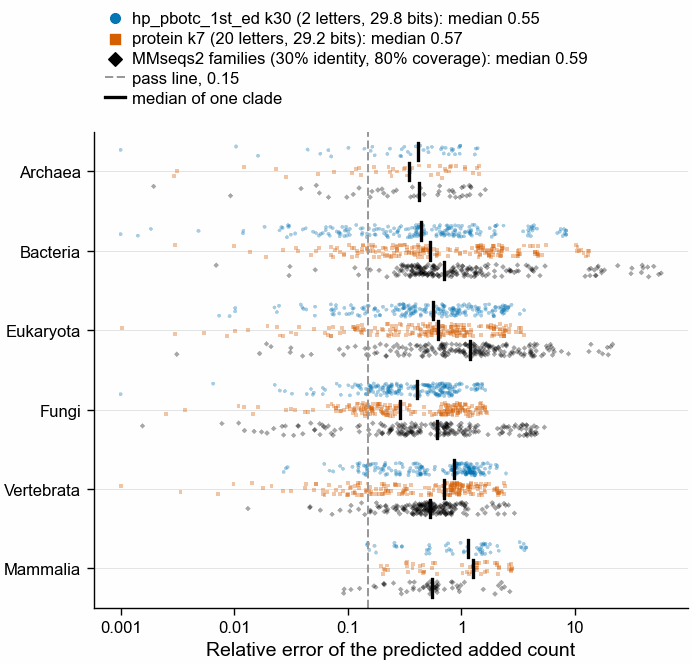

In [8]:
methods = [
    (f"real.{PRIMARY_HP}", COLOUR[HP], "o"),
    (f"real.{PRIMARY_AA}", COLOUR[AA], "s"),
    (f"real.{FAMILY}", COLOUR[FAMILY], "D"),
]
rng = np.random.default_rng(343)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 85)
for j, (s, col, mk) in enumerate(methods):
    for i, c in enumerate(CLADES):
        e = (
            splits.filter((pl.col("setting") == s) & (pl.col("clade") == c))[
                "relative_error"
            ]
            .drop_nans()
            .drop_nulls()
        )
        if e.len() == 0:
            continue
        y0 = i + (j - 1) * 0.25
        ax.scatter(
            np.clip(e, 1e-3, None),
            y0 + rng.uniform(-0.08, 0.08, e.len()),
            s=2,
            color=col,
            alpha=0.35,
            edgecolor="none",
            marker=mk,
        )
        ax.plot([e.median()] * 2, [y0 - 0.11, y0 + 0.11], color="black", lw=1.2)
    ax.scatter(
        [],
        [],
        s=12,
        color=col,
        marker=mk,
        label=f"{LABEL[s.removeprefix('real.')]}: "
        f"median {primary[s]['weighted_median']:.2f}",
    )
ax.axvline(
    PASS_MAX_ERROR, color=pf.GREY, ls="--", lw=0.8, label=f"pass line, {PASS_MAX_ERROR}"
)
ax.plot([], [], color="black", lw=1.2, label="median of one clade")
ax.set_xscale("log")
plain = FuncFormatter(lambda v, _: f"{v:g}")
ax.xaxis.set_major_locator(FixedLocator([0.001, 0.01, 0.1, 1, 10, 100]))
ax.xaxis.set_major_formatter(plain)
ax.xaxis.set_minor_locator(NullLocator())
ax.set_yticks(range(len(CLADES)), CLADES)
ax.set_ylim(len(CLADES) - 0.5, -0.5)
ax.grid(axis="y", color="#dddddd", lw=0.3)
ax.set_xlabel("Relative error of the predicted added count")
pf.shared_legend(fig, ncol=1)
pf.save(
    fig, FIG / "345_SF5_next_proteome_prediction_error_hp30_protein7_mmseqs_qfo2020_04"
)

**Supplementary Figure 5 (SF5). How well Heaps' law, fitted on 80% of a clade, predicts
what the next proteome adds.** One faint point per split; the table in section 4 gives
how many splits each method has. The black bar is the clade's median. Blue circles:
`hp_pbotc_1st_ed` k = 30 words; orange squares: 20 amino acids k = 7 words; black
diamonds: MMseqs2 families. Left is better; the dashed line is the pre-registered pass
line. The legend gives each method's median over all splits with the clades weighted
equally, the number the verdict uses. Errors below 0.001 are drawn at 0.001.

### 4b. How much error comes from the shape of Heaps' law alone

Found by the second review: Heaps' law cannot follow a curve that starts at
$U(1) = 0$ exactly. Take the simplest noise-free case, where every pair of proteomes shares
the same number of words, so $U(n) = n(n-1)/2$. Fitting $\kappa n^\gamma$ on
$n = 2, \dots, n_0$ and predicting the next step already gives the error below, before any
real data. A FAIL near this number can come from the model's shape and not from the words.
The synthetic proteomes' median error is a second reference: composition alone, the same
fit. Neither changes the pre-registered verdict; both are context for it.

In [9]:
sys.path.insert(0, str(REPO / "nextflow-runs" / "proteome-novelty" / "bin"))
import novelty as nv

floor = []
for c in CLADES:
    N = clade_members(c).height
    n0 = N - int(np.ceil(0.2 * N))
    n = np.arange(1, n0 + 1)
    k, g = nv.heaps_fit(n * (n - 1) / 2, n0)
    pred = k * ((n0 + 1) ** g - n0**g)
    floor.append(
        {
            "clade": c,
            "N": N,
            "n0": n0,
            "pairs_curve_gamma": g,
            "pairs_curve_relative_error": abs(pred - n0) / n0,
        }
    )
floor = pl.DataFrame(floor)
print(floor)
null_med = test_stats(f"null.{PRIMARY_HP}", common)[0]["weighted_median"]
print(
    f"\nSynthetic proteomes, {HP} k30: median relative error {null_med:.3f} (same clades, same splits)"
)

shape: (6, 5)
┌────────────┬─────┬─────┬───────────────────┬────────────────────────────┐
│ clade      ┆ N   ┆ n0  ┆ pairs_curve_gamma ┆ pairs_curve_relative_error │
│ ---        ┆ --- ┆ --- ┆ ---               ┆ ---                        │
│ str        ┆ i64 ┆ i64 ┆ f64               ┆ f64                        │
╞════════════╪═════╪═════╪═══════════════════╪════════════════════════════╡
│ Archaea    ┆ 7   ┆ 5   ┆ 2.516             ┆ 0.204                      │
│ Bacteria   ┆ 23  ┆ 18  ┆ 2.235             ┆ 0.163                      │
│ Eukaryota  ┆ 48  ┆ 38  ┆ 2.148             ┆ 0.122                      │
│ Fungi      ┆ 12  ┆ 9   ┆ 2.359             ┆ 0.196                      │
│ Vertebrata ┆ 13  ┆ 10  ┆ 2.337             ┆ 0.192                      │
│ Mammalia   ┆ 8   ┆ 6   ┆ 2.461             ┆ 0.205                      │
└────────────┴─────┴─────┴───────────────────┴────────────────────────────┘

Synthetic proteomes, hp_pbotc_1st_ed k30: median relative error 0.282 (sa

shape: (6, 4)
┌────────────┬────────────────────────────┬──────────────────┬─────────────┐
│ clade      ┆ pairs_curve_relative_error ┆ synthetic_median ┆ real_median │
│ ---        ┆ ---                        ┆ ---              ┆ ---         │
│ str        ┆ f64                        ┆ f64              ┆ f64         │
╞════════════╪════════════════════════════╪══════════════════╪═════════════╡
│ Archaea    ┆ 0.204                      ┆ 0.478            ┆ 0.415       │
│ Bacteria   ┆ 0.163                      ┆ 0.508            ┆ 0.444       │
│ Eukaryota  ┆ 0.122                      ┆ 0.424            ┆ 0.568       │
│ Fungi      ┆ 0.196                      ┆ 0.297            ┆ 0.411       │
│ Vertebrata ┆ 0.192                      ┆ 0.264            ┆ 0.854       │
│ Mammalia   ┆ 0.205                      ┆ 0.232            ┆ 1.135       │
└────────────┴────────────────────────────┴──────────────────┴─────────────┘


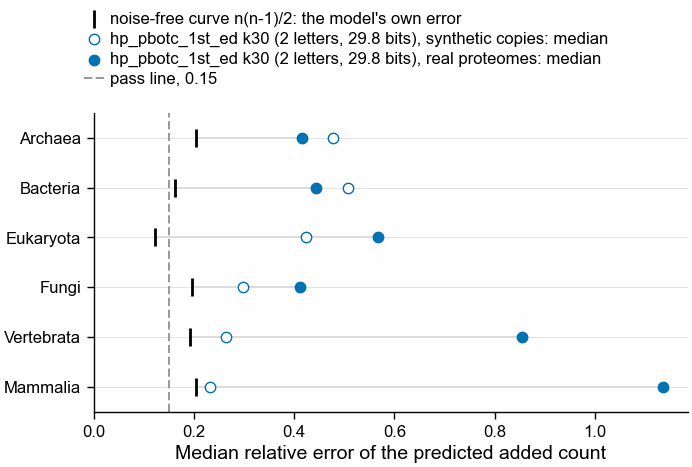

In [10]:
real_pc = test_stats(f"real.{PRIMARY_HP}", common)[1]
null_pc = test_stats(f"null.{PRIMARY_HP}", common)[1]
floor_vs = (
    floor.select("clade", "pairs_curve_relative_error")
    .join(
        null_pc.select("clade", pl.col("median").alias("synthetic_median")),
        on="clade",
        how="left",
    )
    .join(
        real_pc.select("clade", pl.col("median").alias("real_median")),
        on="clade",
        how="left",
    )
)
print(floor_vs)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 60)
y = {c: i for i, c in enumerate(CLADES)}
for r in floor_vs.iter_rows(named=True):
    ax.plot(
        [r["pairs_curve_relative_error"], r["real_median"]],
        [y[r["clade"]]] * 2,
        color="#dddddd",
        lw=0.8,
        zorder=0,
    )
ax.scatter(
    floor_vs["pairs_curve_relative_error"],
    [y[c] for c in floor_vs["clade"]],
    marker="|",
    s=40,
    color="black",
    label="noise-free curve n(n-1)/2: the model's own error",
)
ax.scatter(
    floor_vs["synthetic_median"],
    [y[c] for c in floor_vs["clade"]],
    marker="o",
    s=14,
    facecolor="white",
    edgecolor=COLOUR[HP],
    label=f"{LABEL[PRIMARY_HP]}, synthetic copies: median",
)
ax.scatter(
    floor_vs["real_median"],
    [y[c] for c in floor_vs["clade"]],
    marker="o",
    s=14,
    color=COLOUR[HP],
    label=f"{LABEL[PRIMARY_HP]}, real proteomes: median",
)
ax.axvline(
    PASS_MAX_ERROR, color=pf.GREY, ls="--", lw=0.8, label=f"pass line, {PASS_MAX_ERROR}"
)
ax.set_yticks(range(len(CLADES)), CLADES)
ax.set_ylim(len(CLADES) - 0.5, -0.5)
ax.grid(axis="y", color="#dddddd", lw=0.3)
ax.set_xlim(0, None)
ax.set_xlabel("Median relative error of the predicted added count")
pf.shared_legend(fig, ncol=1)
pf.save(fig, FIG / "345_SF5b_heaps_fit_error_floor_vs_real_synthetic_hp30_qfo2020_04")

**Supplementary Figure 5b (SF5b). In Vertebrata and Mammalia the real proteomes miss by
more than this illustrative curve or the fitted Markov null predicts; in Archaea and Bacteria they miss
by less than their synthetic copies.** Per clade, from left to right in most rows: black tick, the error
Heaps' law makes on a curve with no noise at all, $U(n) = n(n-1)/2$; open blue circle, the
median error on the synthetic copies; filled blue circle, the median error on the real
proteomes (`hp_pbotc_1st_ed` k = 30, the same splits as SF5). Left is better; the dashed
line is the pre-registered pass line. A filled circle far right of both the tick and the open
circle shows a larger error in real data than in these two references. It does not isolate
residue order from all effects of composition, model fit and phylogeny.

## 5. The sequencing decision, per clade

At the 30-bit `hp_pbotc_1st_ed` setting, the full-clade fit predicts what one more
proteome would add:
$\hat\kappa\,\big((N+1)^{\hat\gamma} - N^{\hat\gamma}\big)$. The pre-registered rule says
sequence another when that is at least 1% of $U(N)$ and at least twice what the synthetic
proteomes' fit predicts for their next copy.

The figure shows, for every proteome, how many words would become shared if it had been
sequenced last (words it holds with exactly one other proteome of the clade). That is the
measured version of the prediction, one value per species.

shape: (6, 14)
┌────────────┬─────┬───────┬─────────────────┬──────────────┬────────────────┬──────────────────────────┬───────────────┬─────────────────────┬────────────┬──────────────────┬─────────────┬───────────────────┬──────────────────┐
│ clade      ┆ N   ┆ gamma ┆ gamma_synthetic ┆ U(N)         ┆ predicted_next ┆ predicted_next_synthetic ┆ share_of_U(N) ┆ fold_over_synthetic ┆ most_added ┆ most_added_words ┆ least_added ┆ least_added_words ┆ sequence_another │
│ ---        ┆ --- ┆ ---   ┆ ---             ┆ ---          ┆ ---            ┆ ---                      ┆ ---           ┆ ---                 ┆ ---        ┆ ---              ┆ ---         ┆ ---               ┆ ---              │
│ str        ┆ i64 ┆ f64   ┆ f64             ┆ f64          ┆ f64            ┆ f64                      ┆ f64           ┆ f64                 ┆ str        ┆ f64              ┆ str         ┆ f64               ┆ bool             │
╞════════════╪═════╪═══════╪═════════════════╪══════════════╪════════

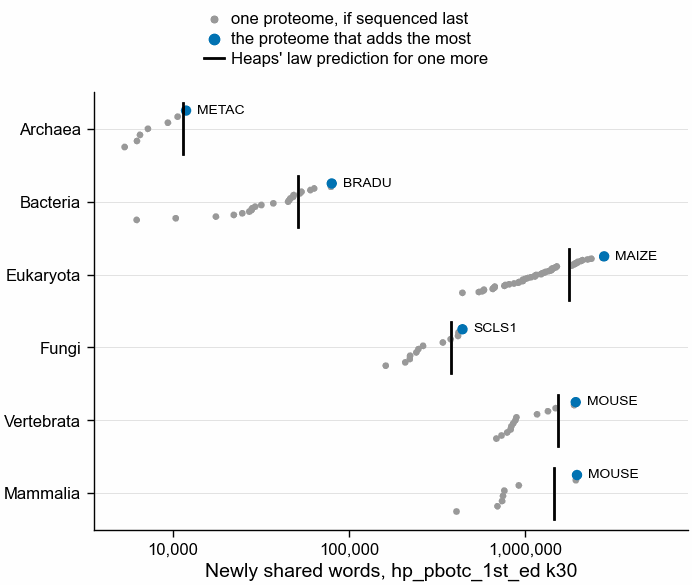

In [11]:
def predicted_next(clade, setting):
    d = fit.filter((pl.col("clade") == clade) & (pl.col("setting") == setting))
    if d.height == 0:
        return np.nan
    k, g, N = d["kappa"][0], d["gamma"][0], d["size"][0]
    return float(k * ((N + 1) ** g - N**g))


rows = []
for c in CLADES:
    real_next, null_next = predicted_next(c, f"real.{PRIMARY_HP}"), predicted_next(
        c, f"null.{PRIMARY_HP}"
    )
    u_n = fit.filter(
        (pl.col("clade") == c) & (pl.col("setting") == f"real.{PRIMARY_HP}")
    )["U_full"]
    u_n = float(u_n[0]) if u_n.len() else np.nan
    lc = last.filter(
        (pl.col("clade") == c) & (pl.col("setting") == f"real.{PRIMARY_HP}")
    )
    lc = lc.join(proteomes.select("proteome", "oscode", "species"), on="proteome").sort(
        ["added_if_last", "proteome"], descending=[True, False]
    )
    rows.append(
        {
            "clade": c,
            "N": clade_members(c).height,
            "gamma": gamma_of(c, f"real.{PRIMARY_HP}"),
            "gamma_synthetic": gamma_of(c, f"null.{PRIMARY_HP}"),
            "U(N)": u_n,
            "predicted_next": real_next,
            "predicted_next_synthetic": null_next,
            "share_of_U(N)": real_next / u_n,
            # Synthetic proteomes that add nothing make any real addition infinitely larger;
            # a missing fit stays missing.
            "fold_over_synthetic": (
                np.nan
                if not np.isfinite(null_next)
                else real_next / null_next if null_next > 0 else np.inf
            ),
            "most_added": lc["oscode"][0] if lc.height else None,
            "most_added_words": float(lc["added_if_last"][0]) if lc.height else np.nan,
            "least_added": lc["oscode"][-1] if lc.height else None,
            "least_added_words": (
                float(lc["added_if_last"][-1]) if lc.height else np.nan
            ),
        }
    )
# polars orders NaN above every number, so NaN >= 0.01 is True: decide only where both
# numbers exist.
decision = pl.DataFrame(rows).with_columns(
    pl.when(pl.col("share_of_U(N)").is_nan() | pl.col("fold_over_synthetic").is_nan())
    .then(None)
    .otherwise(
        (pl.col("share_of_U(N)") >= DECIDE_MIN_SHARE)
        & (pl.col("fold_over_synthetic") >= DECIDE_NULL_FOLD)
    )
    .alias("sequence_another")
)
print(decision)

# Found by the second review: the 1% test holds for any gamma above ln(1.01) / ln(1 + 1/N),
# far below every fitted gamma here, so the 2x synthetic test is the one that decides.
print("\nSmallest gamma at which the 1% test holds:")
print(
    pl.DataFrame(
        {"clade": CLADES, "N": [clade_members(c).height for c in CLADES]}
    ).with_columns(
        (np.log(1 + DECIDE_MIN_SHARE) / (1 + 1 / pl.col("N")).log()).alias(
            "min_gamma_for_1pct"
        )
    )
)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 75)
for i, c in enumerate(CLADES):
    lc = (
        last.filter(
            (pl.col("clade") == c) & (pl.col("setting") == f"real.{PRIMARY_HP}")
        )
        .join(proteomes.select("proteome", "oscode"), on="proteome")
        .sort(["added_if_last", "proteome"], descending=[True, False])
    )
    if lc.height == 0:
        continue
    v = np.clip(lc["added_if_last"].to_numpy(), 1, None)
    y = i + np.linspace(-0.25, 0.25, lc.height)
    ax.scatter(v[1:], y[1:], s=6, color=pf.GREY, edgecolor="none")
    ax.scatter(v[:1], y[:1], s=14, color=COLOUR[HP], edgecolor="none")
    ax.annotate(
        lc["oscode"][0],
        (v[0], y[0]),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=5,
    )
    pn = predicted_next(c, f"real.{PRIMARY_HP}")
    if np.isfinite(pn) and pn > 0:
        ax.plot([pn] * 2, [i - 0.35, i + 0.35], color="black", lw=1)
ax.scatter([], [], s=6, color=pf.GREY, label="one proteome, if sequenced last")
ax.scatter([], [], s=14, color=COLOUR[HP], label="the proteome that adds the most")
ax.plot([], [], color="black", lw=1, label="Heaps' law prediction for one more")
ax.set_xscale("log")
shown_values = (
    last.filter(pl.col("setting") == f"real.{PRIMARY_HP}")["added_if_last"]
    .clip(1, None)
    .to_list()
)
shown_values += [
    v
    for v in (predicted_next(c, f"real.{PRIMARY_HP}") for c in CLADES)
    if np.isfinite(v) and v > 0
]
lo, hi = min(shown_values) / 1.5, max(shown_values) * 3
ax.set_xlim(lo, hi)
plain_log_axis(ax.xaxis, lo, hi)
ax.set_yticks(range(len(CLADES)), CLADES)
ax.set_ylim(len(CLADES) - 0.5, -0.5)
ax.grid(axis="y", color="#dddddd", lw=0.3)
ax.set_xlabel(f"Newly shared words, {HP} k30")
pf.shared_legend(fig, ncol=1)
pf.save(fig, FIG / "345_SF6_newly_shared_words_if_sequenced_last_hp30_qfo2020_04")

**Supplementary Figure 6 (SF6). Newly shared `hp_pbotc_1st_ed` k = 30 words each proteome
would bring if it were the last one sequenced.** Grey dots: one per proteome. Blue dot,
labelled with its UniProt species code: the proteome that adds the most. Black bar: what
Heaps' law, fitted on the whole clade, predicts for one more proteome. The x axis spaces
values by ratio. A proteome with 0 is drawn at 1.

### One paragraph per clade

Generated from the table above, so every number is the one printed there.

In [12]:
from IPython.display import Markdown, display

species = dict(zip(proteomes["oscode"], proteomes["species"]))
paras = []
for r in decision.iter_rows(named=True):
    if r["sequence_another"] is None or r["most_added"] is None:
        paras.append(
            f"**{r['clade']}**: no result for `{PRIMARY_HP}` in the tables read (see the missing list at the top)."
        )
        continue
    verdict = (
        "Sequencing another proteome is worth it by the pre-registered rule"
        if r["sequence_another"]
        else "Another proteome is not worth sequencing for new shared sequence by the pre-registered rule"
    )
    paras.append(
        f"**{r['clade']}** ({r['N']} proteomes). {r['U(N)']:,.0f} `hp_pbotc_1st_ed` k30 words are shared by at least "
        f"two of them; gamma is {r['gamma']:.2f} against {r['gamma_synthetic']:.2f} for the synthetic copies. "
        f"One more proteome is predicted to add {r['predicted_next']:,.0f} newly shared words, "
        f"{100 * r['share_of_U(N)']:.1f}% of what is shared now and {r['fold_over_synthetic']:.1f} times what the "
        f"synthetic copies predict. {verdict} (it needs at least {100 * DECIDE_MIN_SHARE:.0f}% and "
        f"{DECIDE_NULL_FOLD:.0f} times). Of the proteomes in hand, {species[r['most_added']]} ({r['most_added']}) "
        f"would have added the most if sequenced last, {r['most_added_words']:,.0f} words; "
        f"{species[r['least_added']]} ({r['least_added']}) the fewest, {r['least_added_words']:,.0f}."
    )
display(Markdown("\n\n".join(paras)))

**Archaea** (7 proteomes). 31,162 `hp_pbotc_1st_ed` k30 words are shared by at least two of them; gamma is 2.22 against 2.42 for the synthetic copies. One more proteome is predicted to add 11,342 newly shared words, 36.4% of what is shared now and 3.5 times what the synthetic copies predict. Sequencing another proteome is worth it by the pre-registered rule (it needs at least 1% and 2 times). Of the proteomes in hand, Methanosarcina acetivorans (strain ATCC 35395 / DSM 2834 / JCM 12185 / C2A) (METAC) would have added the most if sequenced last, 11,856 words; Nitrosopumilus maritimus (strain SCM1) (NITMS) the fewest, 5,307.

**Bacteria** (23 proteomes). 548,470 `hp_pbotc_1st_ed` k30 words are shared by at least two of them; gamma is 1.97 against 2.20 for the synthetic copies. One more proteome is predicted to add 51,348 newly shared words, 9.4% of what is shared now and 1.9 times what the synthetic copies predict. Another proteome is not worth sequencing for new shared sequence by the pre-registered rule (it needs at least 1% and 2 times). Of the proteomes in hand, Bradyrhizobium diazoefficiens (strain JCM 10833 / IAM 13628 / NBRC 14792 / USDA 110) (BRADU) would have added the most if sequenced last, 79,740 words; Mycoplasma genitalium (strain ATCC 33530 / G-37 / NCTC 10195) (MYCGE) the fewest, 6,213.

**Eukaryota** (48 proteomes). 51,192,968 `hp_pbotc_1st_ed` k30 words are shared by at least two of them; gamma is 1.48 against 1.99 for the synthetic copies. One more proteome is predicted to add 1,774,117 newly shared words, 3.5% of what is shared now and 0.6 times what the synthetic copies predict. Another proteome is not worth sequencing for new shared sequence by the pre-registered rule (it needs at least 1% and 2 times). Of the proteomes in hand, Zea mays (Maize) (MAIZE) would have added the most if sequenced last, 2,814,953 words; Schizosaccharomyces pombe (strain 972 / ATCC 24843) (Fission yeast) (SCHPO) the fewest, 440,674.

**Fungi** (12 proteomes). 2,216,608 `hp_pbotc_1st_ed` k30 words are shared by at least two of them; gamma is 1.86 against 2.27 for the synthetic copies. One more proteome is predicted to add 377,980 newly shared words, 17.1% of what is shared now and 1.4 times what the synthetic copies predict. Another proteome is not worth sequencing for new shared sequence by the pre-registered rule (it needs at least 1% and 2 times). Of the proteomes in hand, Sclerotinia sclerotiorum (strain ATCC 18683 / 1980 / Ss-1) (White mold) (Whetzelinia sclerotiorum) (SCLS1) would have added the most if sequenced last, 441,161 words; Schizosaccharomyces pombe (strain 972 / ATCC 24843) (Fission yeast) (SCHPO) the fewest, 161,637.

**Vertebrata** (13 proteomes). 18,183,129 `hp_pbotc_1st_ed` k30 words are shared by at least two of them; gamma is 1.03 against 2.22 for the synthetic copies. One more proteome is predicted to add 1,546,252 newly shared words, 8.5% of what is shared now and 0.8 times what the synthetic copies predict. Another proteome is not worth sequencing for new shared sequence by the pre-registered rule (it needs at least 1% and 2 times). Of the proteomes in hand, Mus musculus (Mouse) (MOUSE) would have added the most if sequenced last, 1,941,204 words; Gorilla gorilla gorilla (Western lowland gorilla) (GORGO) the fewest, 687,363.

**Mammalia** (8 proteomes). 13,643,663 `hp_pbotc_1st_ed` k30 words are shared by at least two of them; gamma is 0.83 against 2.34 for the synthetic copies. One more proteome is predicted to add 1,458,413 newly shared words, 10.7% of what is shared now and 1.2 times what the synthetic copies predict. Another proteome is not worth sequencing for new shared sequence by the pre-registered rule (it needs at least 1% and 2 times). Of the proteomes in hand, Mus musculus (Mouse) (MOUSE) would have added the most if sequenced last, 1,973,557 words; Monodelphis domestica (Gray short-tailed opossum) (MONDO) the fewest, 407,948.

## 6. A newly shared stretch, in residues

For the clade with the lowest $\gamma$ and the clade with the highest (30-bit
`hp_pbotc_1st_ed`), the proteome that adds the most newly shared words if sequenced last,
and its longest run of such words: consecutive windows, each shared with the same one
other proteome and no third. Both sequences are printed with their coordinates (1-based,
inclusive), an amino-acid match line and an encoded match line. The alignment has no gaps:
kmerseek words are ungapped.

In [13]:
gam = decision.filter(pl.col("gamma").is_not_nan()).sort("gamma")
chosen = list(dict.fromkeys([gam["clade"][0], gam["clade"][-1]])) if gam.height else []
print(
    f"Lowest gamma: {chosen[0] if chosen else None}; highest gamma: {chosen[-1] if chosen else None}"
)


def block(name, start, seq, width=60):
    out = []
    for i in range(0, len(seq), width):
        out.append(
            f"{name:<28}{start + i:>6}  {seq[i:i + width]}  {start + i + len(seq[i:i + width]) - 1}"
        )
    return out


shown = []
for c in chosen:
    ex = examples.filter(pl.col("clade") == c)
    if ex.height == 0 or "length" not in ex.columns or ex["length"].is_null().all():
        print(f"\n{c}: no example stretch in the results")
        continue
    e = ex.row(0, named=True)
    shown.append(e)
    sp, pa = proteomes.filter(pl.col("proteome") == e["specimen"]).row(
        0, named=True
    ), proteomes.filter(pl.col("proteome") == e["partner"]).row(0, named=True)
    print(
        f"\n{c}: specimen {sp['species']} ({sp['oscode']}, {e['specimen']}); shared only with "
        f"{pa['species']} ({pa['oscode']}, {e['partner']})"
    )
    print(
        f"{e['n_words']} consecutive newly shared k30 words = {e['length']} residues; the first word occurs "
        f"{e['n_partner_copies']} time(s) in the partner"
    )
    print(
        f"amino acids identical: {e['n_identical']} of {e['length']}; "
        f"hydrophobic/polar letters identical: {e['n_encoded_identical']} of {e['length']}\n"
    )
    w = 60
    for i in range(0, e["length"], w):
        a, b = e["specimen_seq"][i : i + w], e["partner_seq"][i : i + w]
        ea, eb = e["specimen_encoded"][i : i + w], e["partner_encoded"][i : i + w]
        sa, sb = e["specimen_start"] + i, e["partner_start"] + i
        print(
            f"{sp['oscode'] + ' ' + e['specimen_protein']:<34}{sa:>6}  {a}  {sa + len(a) - 1}"
        )
        print(f"{'':<34}{'':>6}  {e['aa_match'][i:i + w]}")
        print(
            f"{pa['oscode'] + ' ' + e['partner_protein']:<34}{sb:>6}  {b}  {sb + len(b) - 1}"
        )
        print(f"{'  hp_pbotc_1st_ed':<34}{sa:>6}  {ea}")
        print(f"{'':<34}{'':>6}  {e['encoded_match'][i:i + w]}")
        print(f"{'':<34}{sb:>6}  {eb}\n")

Lowest gamma: Mammalia; highest gamma: Archaea

Mammalia: specimen Mus musculus (Mouse) (MOUSE, UP000000589); shared only with Rattus norvegicus (Rat) (RAT, UP000002494)
159 consecutive newly shared k30 words = 188 residues; the first word occurs 1 time(s) in the partner
amino acids identical: 188 of 188; hydrophobic/polar letters identical: 188 of 188

MOUSE sp|Q9QYX7|PCLO_MOUSE          2575  SGALGTFSVTPAVTASLFQTVPTSLTQFLPAEASKPEVSAVSSAVPSVAPRSVSIPIPPE  2634
                                          ||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||
RAT sp|Q9JKS6|PCLO_RAT              2591  SGALGTFSVTPAVTASLFQTVPTSLTQFLPAEASKPEVSAVSSAVPSVAPRSVSIPIPPE  2650
  hp_pbotc_1st_ed                   2575  pphhpphphphhhphphhpphhpphpphhhhphpphphphhpphhhphhhpphphhhhhp
                                          ||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||
                                    2591  pphhpphphphhhphphhpphhpphpphhhhphpphphphhpphhhphhhpphphhhhhp

MOUSE sp|Q9QY

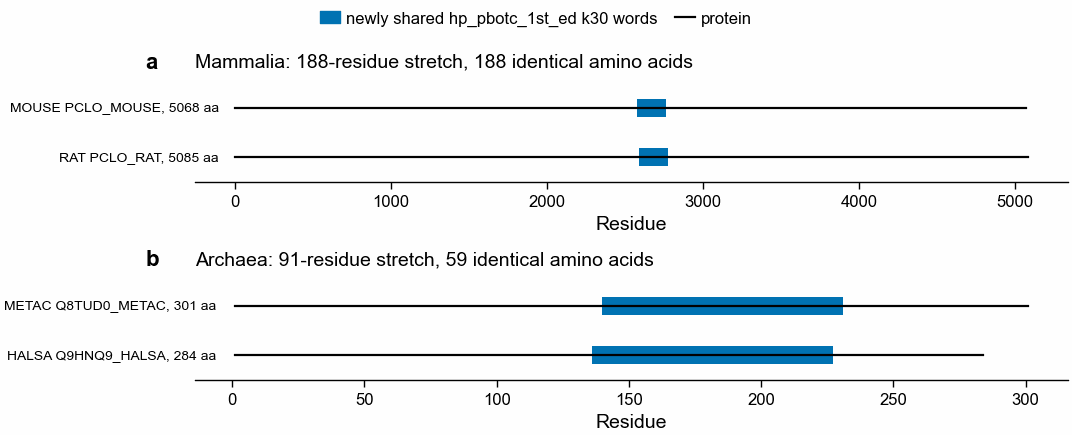

In [14]:
if shown:
    fig, axs = pf.figure(
        pf.TWO_COLUMN_MM * 0.75, 28 * len(shown), nrows=len(shown), squeeze=False
    )
    for ax, e, letter in zip(axs[:, 0], shown, "ab"):
        for y, side in ((1, "specimen"), (0, "partner")):
            L, s0, s1 = e[f"{side}_length"], e[f"{side}_start"], e[f"{side}_end"]
            ax.plot([1, L], [y, y], color="black", lw=0.8)
            ax.add_patch(
                plt.Rectangle((s0, y - 0.18), s1 - s0 + 1, 0.36, color=COLOUR[HP], lw=0)
            )
            code_ = proteomes.filter(pl.col("proteome") == e[side])["oscode"][0]
            ax.text(
                -0.02 * max(e["specimen_length"], e["partner_length"]),
                y,
                f"{code_} {e[f'{side}_protein'].split('|')[-1]}, {L} aa",
                ha="right",
                va="center",
                fontsize=5,
            )
        ax.set_ylim(-0.5, 1.5)
        ax.set_yticks([])
        ax.spines["left"].set_visible(False)
        ax.set_xlabel("Residue")
        ax.set_title(
            f"{e['clade']}: {e['length']}-residue stretch, {e['n_identical']} identical amino acids",
            loc="left",
        )
        pf.panel_label(ax, letter)
    ax.add_patch(
        plt.Rectangle(
            (0, 0), 0, 0, color=COLOUR[HP], label=f"newly shared {HP} k30 words"
        )
    )
    ax.plot([], [], color="black", lw=0.8, label="protein")
    pf.shared_legend(fig, ncol=2)
    pf.save(
        fig, FIG / "345_SF7_newly_shared_stretch_lowest_highest_gamma_hp30_qfo2020_04"
    )

**Supplementary Figure 7 (SF7). Where the printed stretches sit on their proteins.** Black
line: the protein, drawn to length. Blue box: the run of newly shared `hp_pbotc_1st_ed`
k = 30 words. Top line of each panel: the proteome that adds the most if sequenced last;
bottom line: the one other proteome of the clade that holds these words.

## 7. Secondary test (structure): not run

The rule asks for Foldseek structure-cluster rarefaction across clades. That needs
AlphaFold models for every proteome of each clade, and this pipeline fetches none, so the
test is not run here. The rule stays as written in the first cell for a later run.

## 8. Every alphabet and k of the region benchmark's sweep (reported, not in the verdict)

Asked for after the verdict: the section 4 test repeated for the 17 alphabets and the k
values the QfO region benchmark sweeps (`nextflow-runs/qfo-pfam-region-benchmark/main.nf`,
`ALL_ENCODINGS`), real proteomes only. That is 182 alphabet-k pairs: `uniprot18` k14 is
left out because its words need 58.4 bits and the pipeline packs a word into 58. The
splits are the same 898 as in section 4. Run with `make run-sweep` and pulled with
`make pull-sweep` into `tables/345_sweep/`. None of this changes the pre-registered verdict.

**Result (run of 2026-10-20).** No alphabet at any k comes near the 0.15 pass line. The
lowest median error of the 182 is `gbmr4` k13, 0.40; the lowest among the two-letter H/P
alphabets is `hp_thomas_dill2` k27, 0.49; `hp_pbotc_1st_ed` is lowest at k27, 0.495. Below
about k23 the two-letter alphabets have so few possible words (2^k) that almost every one is
already in two proteomes, so most splits have no newly shared word and drop out.

In [15]:
SWEEP = Path(os.environ.get("NB345_SWEEP_DIR", REPO / "tables" / "345_sweep"))
# Panels grouped by letter count, HP family first (rule: group a category axis by what it is).
SWEEP_GROUPS = {
    "2-3 letters (hydrophobic/polar)": [
        "hp_pbotc_1st_ed",
        "hp_lehninger2",
        "hp_lehninger_c_nonpolar2",
        "hp_thomas_dill2",
        "hp_thomas_dill_no_c2",
        "hp_kyte_doolittle2",
        "hp_lehninger_hpc3",
    ],
    "4-7 letters": ["gbmr4", "wwmj5", "dayhoff6", "gbmr7"],
    "12-18 letters": ["mmseqs12", "sdm12", "wass14", "hsdm17", "uniprot18"],
    "20 letters": ["protein"],
}
SWEEP_ALPHABETS = [a for g in SWEEP_GROUPS.values() for a in g]
sweep_file = SWEEP / "345_splits.parquet"
if sweep_file.exists():
    sw = (
        pl.read_parquet(sweep_file)
        .filter(
            pl.col("setting").str.starts_with("real.")
            & (pl.col("setting") != f"real.{FAMILY}")
        )
        .with_columns(
            pl.col("setting").str.split(".").list.get(1).alias("alphabet"),
            pl.col("setting").str.split(".").list.get(2).cast(pl.Int64).alias("k"),
        )
    )
    usable = sw.filter(
        pl.col("relative_error").is_not_nan() & pl.col("relative_error").is_not_null()
    )
    rows = []
    for (a, k), d in usable.group_by(["alphabet", "k"]):
        rows.append(
            {
                "alphabet": a,
                "k": k,
                "weighted_median": weighted_median(
                    d["relative_error"].to_list(), d["clade"].to_list()
                ),
                "splits_used": d.height,
                "clades": d["clade"].n_unique(),
            }
        )
    sweep_table = pl.DataFrame(rows).sort(
        pl.col("alphabet").replace_strict(
            {a: i for i, a in enumerate(SWEEP_ALPHABETS)}, default=99
        ),
        "k",
    )
    sweep_clade = usable.group_by(["alphabet", "k", "clade"]).agg(
        pl.col("relative_error").median().alias("median")
    )
    dropped = (
        sw.filter(pl.col("true_added") == 0)
        .group_by("alphabet", "k")
        .len()
        .rename({"len": "splits_dropped_true_0"})
    )
    sweep_table = sweep_table.join(dropped, on=["alphabet", "k"], how="left").fill_null(
        0
    )
    print(f"{sweep_table.height} alphabet-k pairs with a result; expected 182")
    print(
        "Missing alphabets:",
        sorted(set(SWEEP_ALPHABETS) - set(sweep_table["alphabet"])) or "none",
    )
    with pl.Config(tbl_rows=200):
        print(sweep_table)
    best = sweep_table.sort("weighted_median").head(10)
    print("\nTen lowest errors:")
    print(best)
else:
    sweep_table = None
    print(
        f"No sweep tables in {SWEEP}: run `make run-sweep` on Sherlock, then `make pull-sweep`."
    )

182 alphabet-k pairs with a result; expected 182
Missing alphabets: none
shape: (182, 6)
┌──────────────────────────┬─────┬─────────────────┬─────────────┬────────┬───────────────────────┐
│ alphabet                 ┆ k   ┆ weighted_median ┆ splits_used ┆ clades ┆ splits_dropped_true_0 │
│ ---                      ┆ --- ┆ ---             ┆ ---         ┆ ---    ┆ ---                   │
│ str                      ┆ i64 ┆ f64             ┆ i64         ┆ i64    ┆ u32                   │
╞══════════════════════════╪═════╪═════════════════╪═════════════╪════════╪═══════════════════════╡
│ hp_pbotc_1st_ed          ┆ 18  ┆ 24.092          ┆ 42          ┆ 1      ┆ 856                   │
│ hp_pbotc_1st_ed          ┆ 19  ┆ 3.889           ┆ 42          ┆ 1      ┆ 856                   │
│ hp_pbotc_1st_ed          ┆ 20  ┆ 439.229         ┆ 433         ┆ 4      ┆ 465                   │
│ hp_pbotc_1st_ed          ┆ 21  ┆ 31.968          ┆ 698         ┆ 5      ┆ 200                   │
│ hp_pbotc_

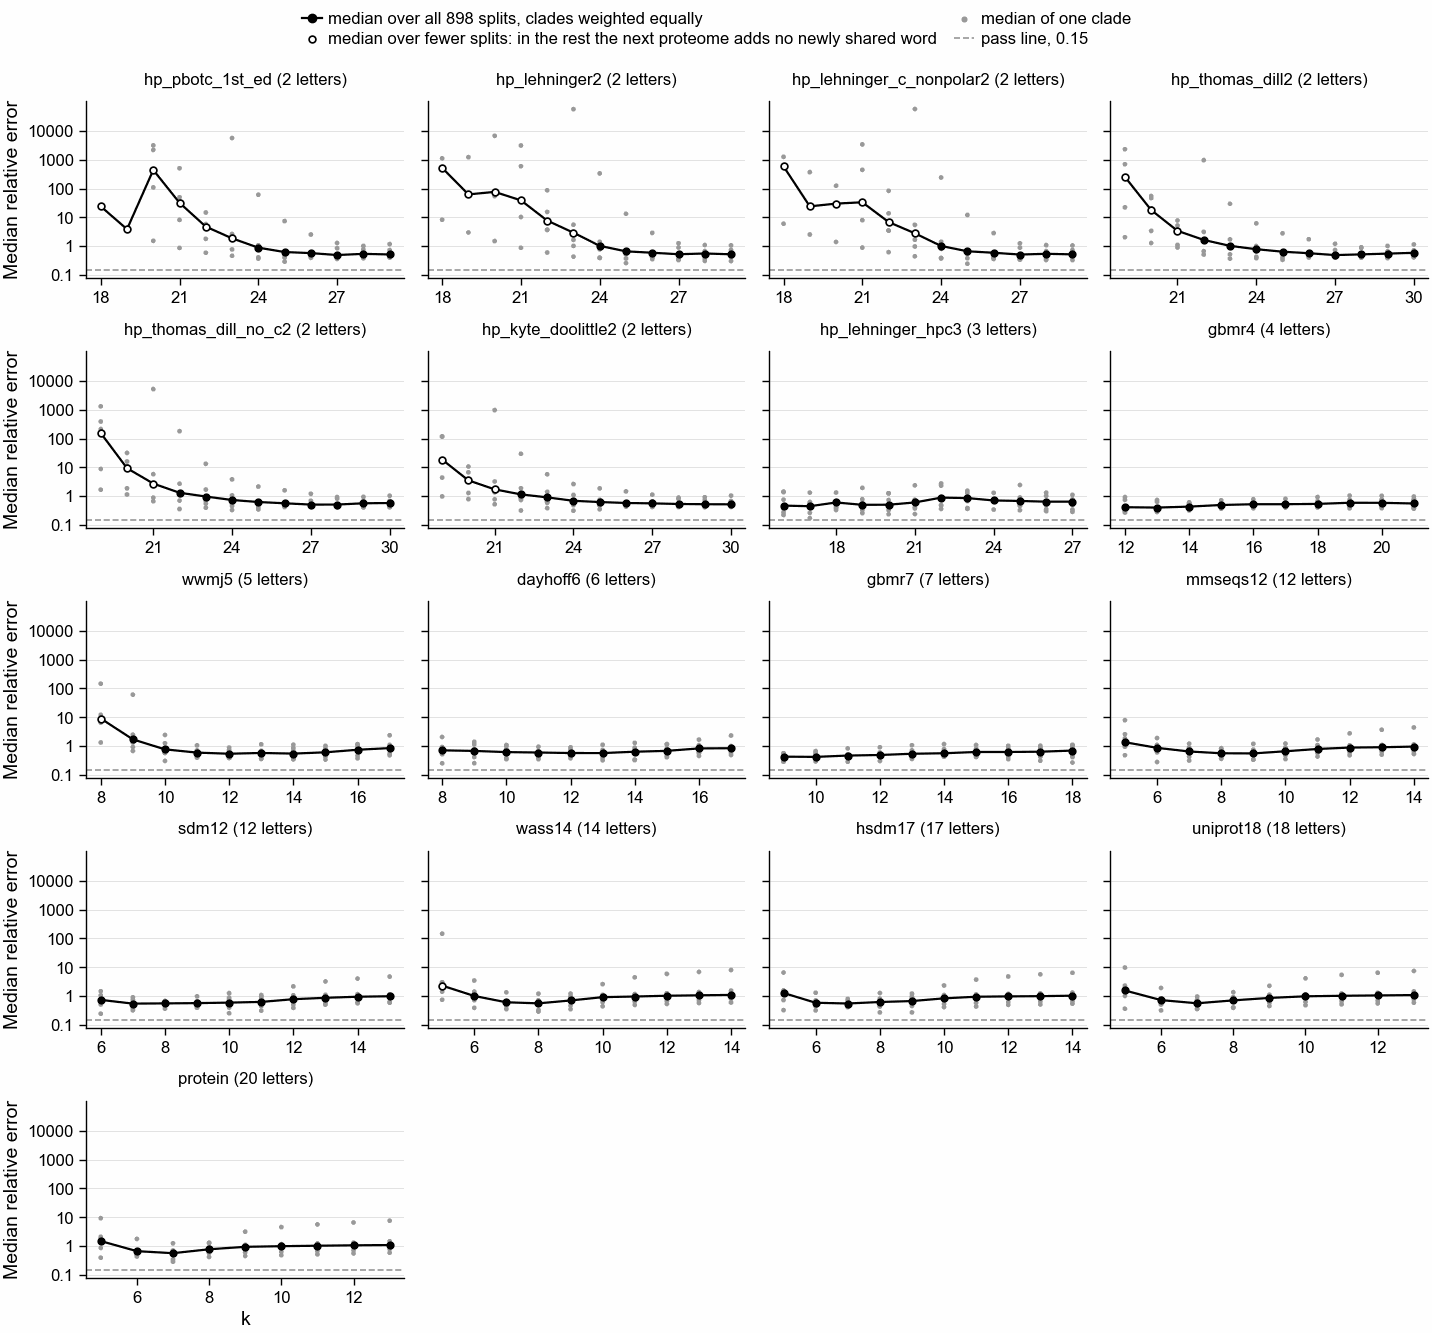

In [16]:
if sweep_table is not None:
    present = [a for a in SWEEP_ALPHABETS if a in set(sweep_table["alphabet"])]
    ncol = 4
    nrow = int(np.ceil(len(present) / ncol))
    fig, axes = pf.figure(
        pf.TWO_COLUMN_MM, 34 * nrow, nrows=nrow, ncols=ncol, sharey=True, squeeze=False
    )
    for ax, a in zip(axes.flat, present):
        t = sweep_table.filter(pl.col("alphabet") == a).sort("k")
        c = sweep_clade.filter(pl.col("alphabet") == a)
        ax.scatter(
            c["k"],
            c["median"].clip(1e-2, None),
            s=3,
            color=pf.GREY,
            edgecolor="none",
            zorder=1,
        )
        ax.plot(t["k"], t["weighted_median"], color="black", lw=0.8, zorder=2)
        full = t.filter(pl.col("splits_dropped_true_0") == 0)
        part = t.filter(pl.col("splits_dropped_true_0") > 0)
        ax.scatter(full["k"], full["weighted_median"], s=6, color="black", zorder=3)
        ax.scatter(
            part["k"],
            part["weighted_median"],
            s=6,
            facecolor="white",
            edgecolor="black",
            lw=0.6,
            zorder=3,
        )
        ax.axhline(PASS_MAX_ERROR, color=pf.GREY, ls="--", lw=0.6, zorder=0)
        ax.set_title(f"{a} ({len(nv.ALPHABETS[a])} letters)", fontsize=6)
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(FixedLocator([0.01, 0.1, 1, 10, 100, 1000, 10000]))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax.yaxis.set_minor_locator(NullLocator())
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
        ax.grid(axis="y", color="#dddddd", lw=0.3)
    for ax in list(axes.flat)[len(present) :]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel("Median relative error")
    for ax in axes[-1, :]:
        ax.set_xlabel("k")
    axes.flat[0].plot(
        [],
        [],
        color="black",
        lw=0.8,
        marker="o",
        ms=2.5,
        label="median over all 898 splits, clades weighted equally",
    )
    axes.flat[0].scatter(
        [],
        [],
        s=6,
        facecolor="white",
        edgecolor="black",
        lw=0.6,
        label="median over fewer splits: in the rest the next proteome adds no newly shared word",
    )
    axes.flat[0].scatter([], [], s=3, color=pf.GREY, label="median of one clade")
    axes.flat[0].plot(
        [], [], color=pf.GREY, ls="--", lw=0.6, label=f"pass line, {PASS_MAX_ERROR}"
    )
    pf.shared_legend(fig, ncol=2)
    pf.save(
        fig,
        FIG / "345_SF8_next_proteome_error_every_alphabet_k_region_sweep_qfo2020_04",
    )

**Supplementary Figure 8 (SF8). How well Heaps' law predicts what the next proteome adds,
for every alphabet and k of the region benchmark's sweep.** One panel per alphabet, grouped
by letter count: hydrophobic/polar alphabets first, then 4-7 letters, 12-18 letters, and
the 20 amino acids. Black line: the median relative error over all splits, clades weighted
equally, the number section 4's verdict uses. A filled circle uses all 898 splits; an open
circle uses fewer, because in the other splits the next proteome adds no newly shared word
(at small k almost every possible word is already in two proteomes), so its error cannot
be computed. Grey dots: each clade's median. Lower is better; the dashed line is the pre-registered pass line, 0.15. Values below 0.01 are drawn
at 0.01. The y axis spaces values by ratio: the step from 0.1 to 1 takes as much room as
the step from 1 to 10.

shape: (12, 4)
┌─────┬─────────────────┬─────────────┬───────────────────────┐
│ k   ┆ weighted_median ┆ splits_used ┆ splits_dropped_true_0 │
│ --- ┆ ---             ┆ ---         ┆ ---                   │
│ i64 ┆ f64             ┆ i64         ┆ u32                   │
╞═════╪═════════════════╪═════════════╪═══════════════════════╡
│ 18  ┆ 24.092          ┆ 42          ┆ 856                   │
│ 19  ┆ 3.889           ┆ 42          ┆ 856                   │
│ 20  ┆ 439.229         ┆ 433         ┆ 465                   │
│ 21  ┆ 31.968          ┆ 698         ┆ 200                   │
│ 22  ┆ 4.778           ┆ 698         ┆ 200                   │
│ 23  ┆ 1.878           ┆ 895         ┆ 3                     │
│ 24  ┆ 0.892           ┆ 898         ┆ 0                     │
│ 25  ┆ 0.629           ┆ 898         ┆ 0                     │
│ 26  ┆ 0.578           ┆ 898         ┆ 0                     │
│ 27  ┆ 0.495           ┆ 898         ┆ 0                     │
│ 28  ┆ 0.544           ┆

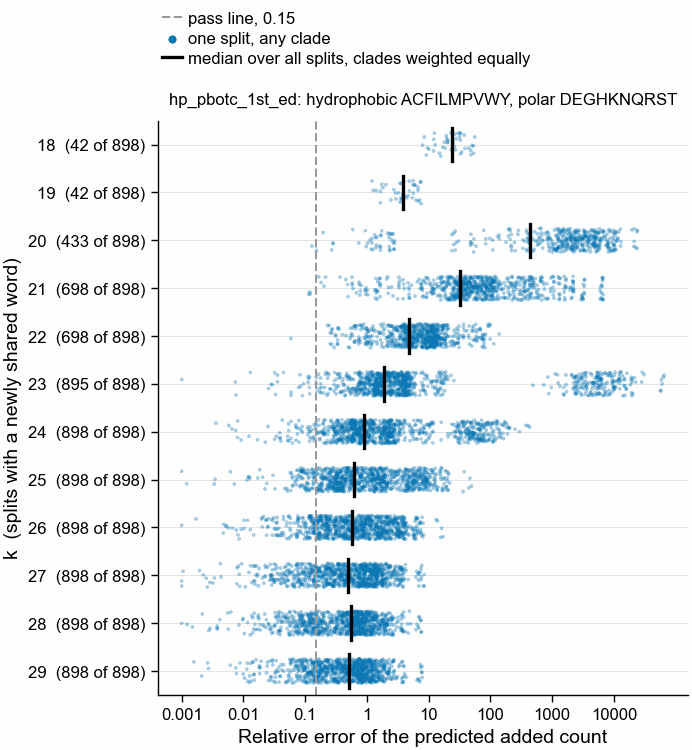

In [17]:
if sweep_table is not None:
    hp_ks = sorted(sweep_table.filter(pl.col("alphabet") == HP)["k"].to_list())
    d = usable.filter(pl.col("alphabet") == HP)
    print(
        sweep_table.filter(pl.col("alphabet") == HP).select(
            "k", "weighted_median", "splits_used", "splits_dropped_true_0"
        )
    )
    fig, ax = pf.figure(pf.ONE_COLUMN_MM, 12 + 7 * len(hp_ks))
    rng = np.random.default_rng(345)
    for i, k in enumerate(hp_ks):
        e = d.filter(pl.col("k") == k)
        ax.scatter(
            np.clip(e["relative_error"], 1e-3, None),
            i + rng.uniform(-0.25, 0.25, e.height),
            s=2,
            color=COLOUR[HP],
            alpha=0.35,
            edgecolor="none",
        )
        m = sweep_table.filter((pl.col("alphabet") == HP) & (pl.col("k") == k))[
            "weighted_median"
        ][0]
        ax.plot([m, m], [i - 0.35, i + 0.35], color="black", lw=1.2)
    ax.axvline(
        PASS_MAX_ERROR,
        color=pf.GREY,
        ls="--",
        lw=0.8,
        label=f"pass line, {PASS_MAX_ERROR}",
    )
    ax.scatter([], [], s=6, color=COLOUR[HP], label="one split, any clade")
    ax.plot(
        [],
        [],
        color="black",
        lw=1.2,
        label="median over all splits, clades weighted equally",
    )
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(
        FixedLocator([0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000])
    )
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_locator(NullLocator())
    used = dict(
        sweep_table.filter(pl.col("alphabet") == HP)
        .select("k", "splits_used")
        .iter_rows()
    )
    ax.set_yticks(range(len(hp_ks)), [f"{k}  ({used[k]} of 898)" for k in hp_ks])
    ax.set_ylim(len(hp_ks) - 0.5, -0.5)
    ax.grid(axis="y", color="#dddddd", lw=0.3)
    ax.set_xlabel("Relative error of the predicted added count")
    ax.set_ylabel("k  (splits with a newly shared word)")
    ax.set_title(f"{HP}: hydrophobic ACFILMPVWY, polar DEGHKNQRST", fontsize=6)
    pf.shared_legend(fig, ncol=1)
    pf.save(
        fig,
        FIG / "345_SF9_next_proteome_error_hp_pbotc_every_k_region_sweep_qfo2020_04",
    )

**Supplementary Figure 9 (SF9). Section 4's test for `hp_pbotc_1st_ed` at every k of the
region benchmark's sweep.** Same layout as SF5, one row per k instead of per clade. Blue
dots: one split each, from any clade; black bar: the median with clades weighted
equally. The number beside each k is how many of the 898 splits have a next proteome that
adds at least one newly shared word; below k23 most do not, so those rows rest on few
splits and few clades. Left is better; the dashed line is the pass line, 0.15. Errors below 0.001 are
drawn at 0.001.

# Summary and Conclusions

## Background

Notebook 345 asks whether one more proteome adds new local sequence or mostly repeats what
a clade already holds. It counts words (windows of k residues) shared by at least two of
the 78 QfO 2020_04 reference proteomes in six clades, fits Heaps' law to how that count
grows, and tests whether the fit predicts what the next proteome adds. The rule was
committed before the run (first cell).

## Summary and Conclusions

* Heaps' law fitted on 80% of a clade misses the next proteome's newly shared
  `hp_pbotc_1st_ed` k30 words by a median 55%, failing the pre-registered 15% bar.
* MMseqs2 families miss by 60%, so H/P words beat families by 8%, not the 25% the rule
  required.
* 20-letter k7 words miss by 57%: the reduced alphabet predicts better overall, but in
  only 3 of 6 clades.
* Heaps' law misses even a noise-free curve by 12–21%, above the 15% pass line in 5 of 6
  clades for this illustrative quadratic curve. This is not a lower bound on error for other data.
* In Mammalia and Vertebrata, real proteomes miss by 114% and 85%, against 23% and 26%
  for synthetic copies with the same composition.
* Only Archaea passes the sequencing rule: one more proteome adds a predicted 11,342
  shared H/P k30 words, 3.5 times its synthetic copies.
* Mouse adds the most newly shared words to Mammalia (1,973,557); its longest run is 188
  residues of piccolo (PCLO), identical in rat and held by no other mammal.

## Analysis Details

The pipeline (`nextflow-runs/proteome-novelty`) counted every k-mer window in each
proteome and in one synthetic copy per proteome, a first-order Markov chain fitted to the
proteome's initial-residue and adjacent-residue frequencies. It preserves lengths exactly,
but not realized residue or residue-pair counts. $U(n)$, the number of words shared by
at least two of $n$ proteomes, was averaged exactly over every order of adding proteomes
(section 2). Real proteomes share 2 to 31 times more 30-bit words than their synthetic
copies when two proteomes are compared, and the excess shrinks as proteomes are added
(SF3). In Eukaryota at all 48 proteomes the synthetic copies share more words than the
real ones (ratio 0.85 for H/P k30). That is chance, not a bug (section 2c): the 48
proteomes hold 382,612,416 windows, a third of the 1,073,741,824 possible H/P k30 words,
and a two-letter Markov model predicts 60.0 million words shared by chance, against 60.1
million for the synthetic copies. Real proteomes repeat words within a proteome, so they
hold fewer distinct words (231 million against 308 million) and match fewer by chance.

The primary test (section 4) used the same 898 splits for every setting. All three
methods miss by more than half the true value. Section 4b shows that part of the miss is
the model's shape: a curve where every pair of proteomes shares the same number of words
already gives 12–21% error, and the pass line of 15% sits inside that range. In Archaea,
Bacteria, Eukaryota and Fungi the real error (41–57%) is close to the synthetic error
(30–51%), but this agreement does not establish which effects cause the real-data error. In Vertebrata and
Mammalia the real error is three to five times the synthetic error: closely related
proteomes share long identical stretches, and how much the next one adds depends on which
species it is, not on a smooth curve.

The sequencing decision (section 5) needs the predicted addition to be at least 1% of
what is shared and at least twice the synthetic prediction. Every clade clears 1%; only
Archaea clears the twofold test (3.5 times). The structure test (section 7) was not run,
because the pipeline fetches no AlphaFold models.

## Supplementary Information

- Sherlock run: job 48470695, 2026-10-19, 325 tasks, none failed; code at commit 260700d
  of branch `olgabot/nb343-proteome-novelty`. Tables pulled with `make pull-results`
  into `tables/345/`.
- MMseqs2 release 18, `easy-cluster --min-seq-id 0.3 -c 0.8 --cov-mode 0`, image pinned
  by digest in `nextflow-runs/proteome-novelty/main.nf`.
- FracMinHash scaled value 1 (every word kept).
- The 21-bit and 42-bit budgets are reported in sections 2b and 4 and do not enter the
  verdict. At 21 bits H/P k21 misses by a median 3,197%, and all 200 Eukaryota splits
  are dropped there because the next proteome adds no newly shared word.
- Figures: `figures/345/345_SF1` to `345_SF7` (PNG, SVG, PDF).

In [18]:
summary_md = "\n# Summary and Conclusions\n\n## Background\n\nNotebook 345 asks whether one more proteome adds new local sequence or mostly repeats what\na clade already holds. It counts words (windows of k residues) shared by at least two of\nthe 78 QfO 2020_04 reference proteomes in six clades, fits Heaps' law to how that count\ngrows, and tests whether the fit predicts what the next proteome adds. The rule was\ncommitted before the run (first cell).\n\n## Summary and Conclusions\n\n* Heaps' law fitted on 80% of a clade misses the next proteome's newly shared\n  `hp_pbotc_1st_ed` k30 words by a median 55%, failing the pre-registered 15% bar.\n* MMseqs2 families miss by 60%, so H/P words beat families by 8%, not the 25% the rule\n  required.\n* 20-letter k7 words miss by 57%: the reduced alphabet predicts better overall, but in\n  only 3 of 6 clades.\n* Heaps' law misses even a noise-free curve by 12–21%, above the 15% pass line in 5 of 6\n  clades for this illustrative quadratic curve. This is not a lower bound on error for other data.\n* In Mammalia and Vertebrata, real proteomes miss by 114% and 85%, against 23% and 26%\n  for synthetic copies with the same composition.\n* Only Archaea passes the sequencing rule: one more proteome adds a predicted 11,342\n  shared H/P k30 words, 3.5 times its synthetic copies.\n* Mouse adds the most newly shared words to Mammalia (1,973,557); its longest run is 188\n  residues of piccolo (PCLO), identical in rat and held by no other mammal.\n\n## Analysis Details\n\nThe pipeline (`nextflow-runs/proteome-novelty`) counted every k-mer window in each\nproteome and in one synthetic copy per proteome, a first-order Markov chain fitted to the\nproteome's initial-residue and adjacent-residue frequencies. It preserves lengths exactly,\nbut not realized residue or residue-pair counts. $U(n)$, the number of words shared by\nat least two of $n$ proteomes, was averaged exactly over every order of adding proteomes\n(section 2). Real proteomes share 2 to 31 times more 30-bit words than their synthetic\ncopies when two proteomes are compared, and the excess shrinks as proteomes are added\n(SF3). In Eukaryota at all 48 proteomes the synthetic copies share more words than the\nreal ones (ratio 0.85 for H/P k30). That is chance, not a bug (section 2c): the 48\nproteomes hold 382,612,416 windows, a third of the 1,073,741,824 possible H/P k30 words,\nand a two-letter Markov model predicts 60.0 million words shared by chance, against 60.1\nmillion for the synthetic copies. Real proteomes repeat words within a proteome, so they\nhold fewer distinct words (231 million against 308 million) and match fewer by chance.\n\nThe primary test (section 4) used the same 898 splits for every setting. All three\nmethods miss by more than half the true value. Section 4b shows that part of the miss is\nthe model's shape: a curve where every pair of proteomes shares the same number of words\nalready gives 12–21% error, and the pass line of 15% sits inside that range. In Archaea,\nBacteria, Eukaryota and Fungi the real error (41–57%) is close to the synthetic error\n(30–51%), but this agreement does not establish which effects cause the real-data error. In Vertebrata and\nMammalia the real error is three to five times the synthetic error: closely related\nproteomes share long identical stretches, and how much the next one adds depends on which\nspecies it is, not on a smooth curve.\n\nThe sequencing decision (section 5) needs the predicted addition to be at least 1% of\nwhat is shared and at least twice the synthetic prediction. Every clade clears 1%; only\nArchaea clears the twofold test (3.5 times). The structure test (section 7) was not run,\nbecause the pipeline fetches no AlphaFold models.\n\n## Supplementary Information\n\n- Sherlock run: job 48470695, 2026-10-19, 325 tasks, none failed; code at commit 260700d\n  of branch `olgabot/nb343-proteome-novelty`. Tables pulled with `make pull-results`\n  into `tables/345/`.\n- MMseqs2 release 18, `easy-cluster --min-seq-id 0.3 -c 0.8 --cov-mode 0`, image pinned\n  by digest in `nextflow-runs/proteome-novelty/main.nf`.\n- FracMinHash scaled value 1 (every word kept).\n- The 21-bit and 42-bit budgets are reported in sections 2b and 4 and do not enter the\n  verdict. At 21 bits H/P k21 misses by a median 3,197%, and all 200 Eukaryota splits\n  are dropped there because the next proteome adds no newly shared word.\n- Figures: `figures/345/345_SF1` to `345_SF7` (PNG, SVG, PDF).\n"
print(summary_md)


# Summary and Conclusions

## Background

Notebook 345 asks whether one more proteome adds new local sequence or mostly repeats what
a clade already holds. It counts words (windows of k residues) shared by at least two of
the 78 QfO 2020_04 reference proteomes in six clades, fits Heaps' law to how that count
grows, and tests whether the fit predicts what the next proteome adds. The rule was
committed before the run (first cell).

## Summary and Conclusions

* Heaps' law fitted on 80% of a clade misses the next proteome's newly shared
  `hp_pbotc_1st_ed` k30 words by a median 55%, failing the pre-registered 15% bar.
* MMseqs2 families miss by 60%, so H/P words beat families by 8%, not the 25% the rule
  required.
* 20-letter k7 words miss by 57%: the reduced alphabet predicts better overall, but in
  only 3 of 6 clades.
* Heaps' law misses even a noise-free curve by 12–21%, above the 15% pass line in 5 of 6
  clades for this illustrative quadratic curve. This is not a lower bound on er

## References

Checked against PubMed on 2026-10-18.

- Altenhoff, Adrian M., Javier Garrayo-Ventas, Salvatore Cosentino, David Emms, Natasha M.
  Glover, Ana Hernández-Plaza, Yannis Nevers, et al. "The Quest for Orthologs Benchmark
  Service and Consensus Calls in 2020." *Nucleic Acids Research* 48, no. W1 (2020):
  W538–45. https://doi.org/10.1093/nar/gkaa308

  **Note:** the reference proteome set this notebook uses is that paper's 2020 release
  (QfO 2020_04).
- Rahman Hera, Mahmudur, N. Tessa Pierce-Ward, and David Koslicki. "Deriving Confidence
  Intervals for Mutation Rates across a Wide Range of Evolutionary Distances Using
  FracMinHash." *Genome Research* 33, no. 7 (2023): 1061–68.
  https://doi.org/10.1101/gr.277651.123

  **Note:** the definition of a FracMinHash sketch with scaled value $s$.
- Steinegger, Martin, and Johannes Söding. "MMseqs2 Enables Sensitive Protein Sequence
  Searching for the Analysis of Massive Data Sets." *Nature Biotechnology* 35, no. 11
  (2017): 1026–28. https://doi.org/10.1038/nbt.3988
- Tettelin, Hervé, David Riley, Ciro Cattuto, and Duccio Medini. "Comparative Genomics:
  The Bacterial Pan-Genome." *Current Opinion in Microbiology* 11, no. 5 (2008): 472–77.
  https://doi.org/10.1016/j.mib.2008.09.006

  **Note:** models of how a pan-genome's size grows with the number of genomes sequenced,
  the gene-level form of the question asked here.